In [291]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 

from matplotlib import pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [293]:
import importlib
import functions
importlib.reload(functions)

<module 'functions' from '/Users/peytaguo/Desktop/ASC/Nucelar Resonance Analysis /functions.py'>

In [10]:
ne_amu = 19.9869544
a_amu = 4.001506179129

mg_amu = 23.9784588
uc2 = 931.494 #MeV

energy_threshold = (ne_amu + a_amu - mg_amu)*uc2
print(energy_threshold)

9.316597247987401


In [11]:
sigma = np.load("data/peyta_sigma1.npy")
dsigma = np.load("data/peyta_dsigma1.npy")
theta_cm = np.load("data/peyta_theta_cm1.npy")
ke_cm = np.load("data/peyta_ke_cm1.npy")

rounded_theta_cm = np.round(theta_cm, 1)
rounded_theta_cm[rounded_theta_cm == 53.2] = 53.1
rounded_theta_cm[rounded_theta_cm == 143.2] = 143.1
rounded_theta_cm[rounded_theta_cm == 155.7] = 155.8

print( np.unique( rounded_theta_cm ) )
print(len(np.unique(rounded_theta_cm)))

[ 53.1  58.8  70.   75.5  86.2  91.4 101.6 106.5 116.2 125.5 130.  138.8
 143.1 155.8 163.9 168. ]
16


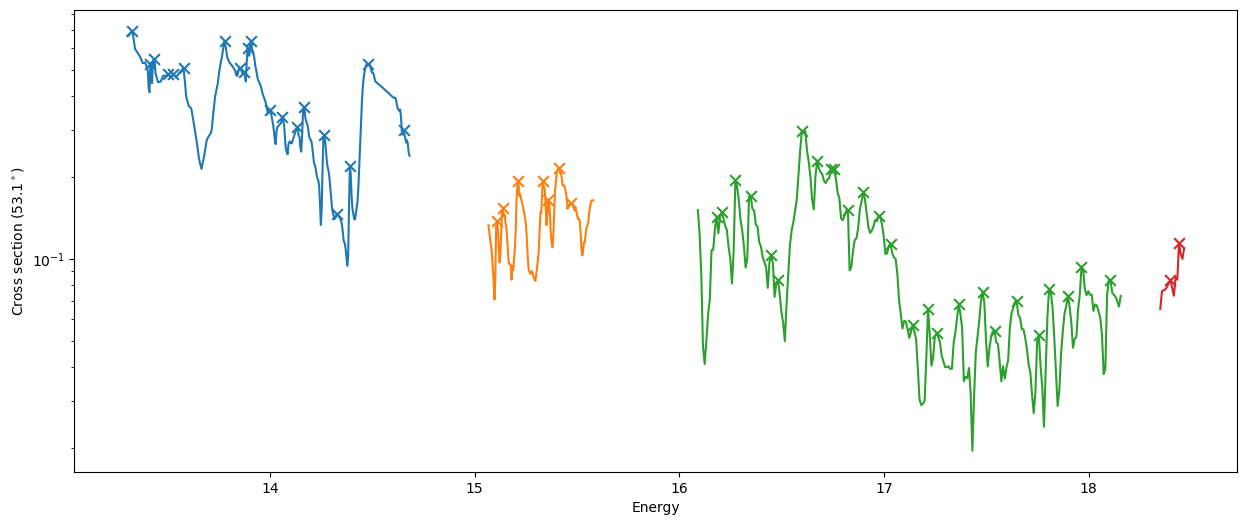

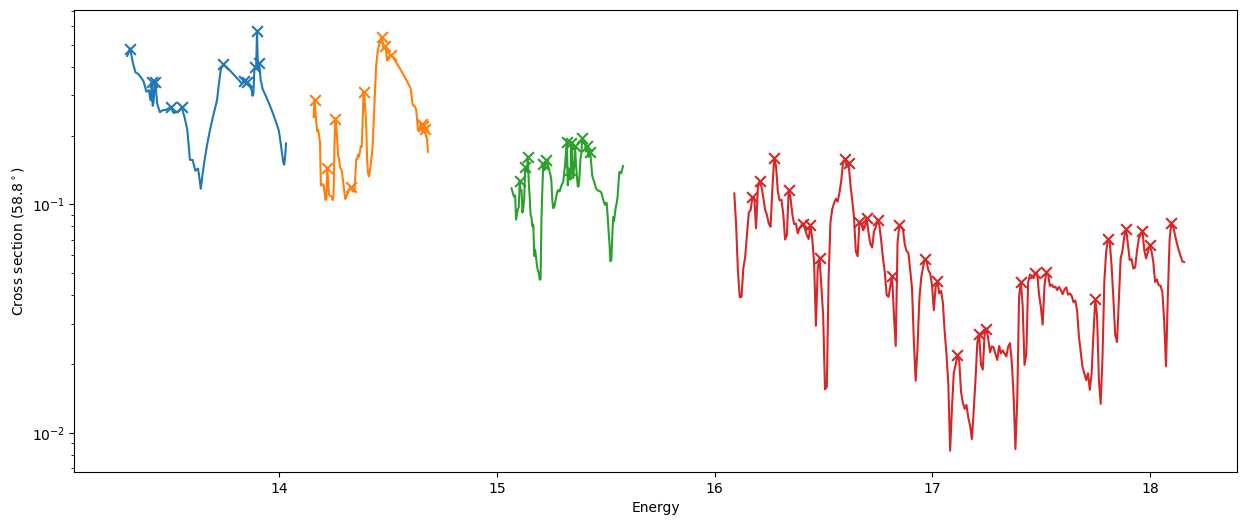

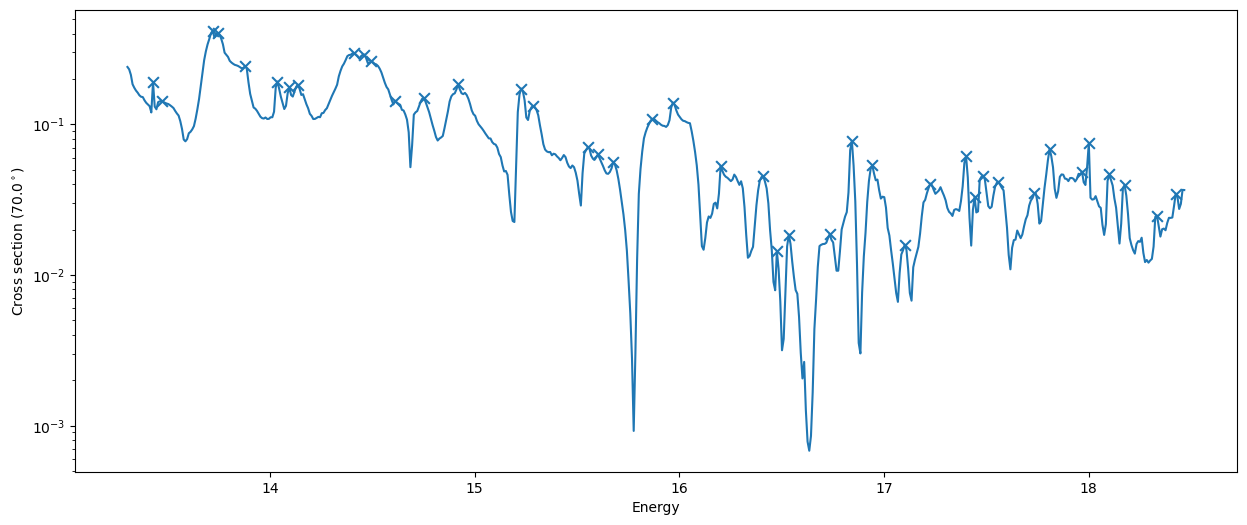

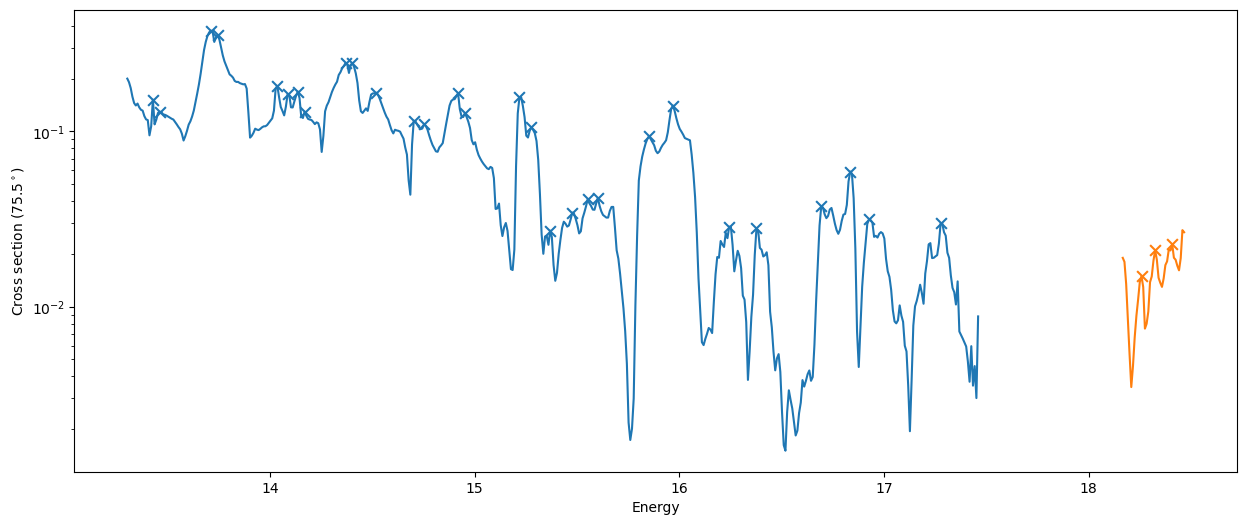

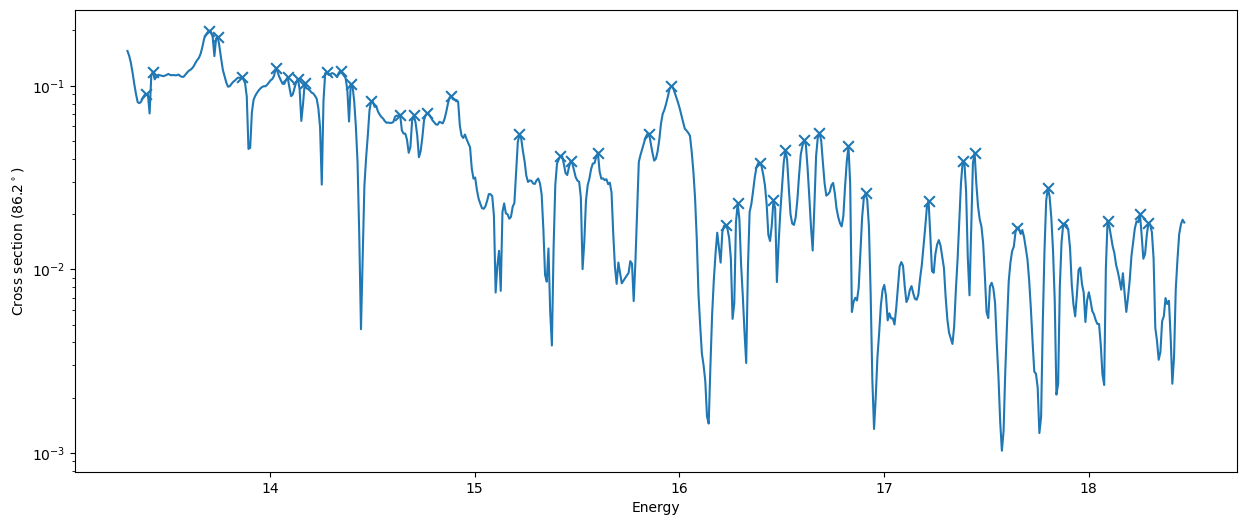

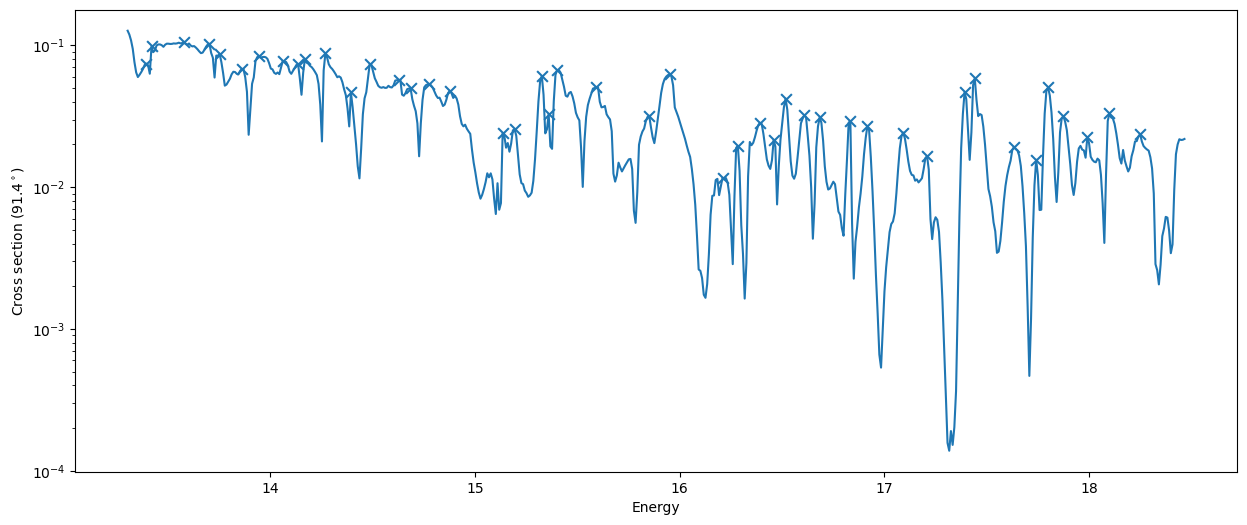

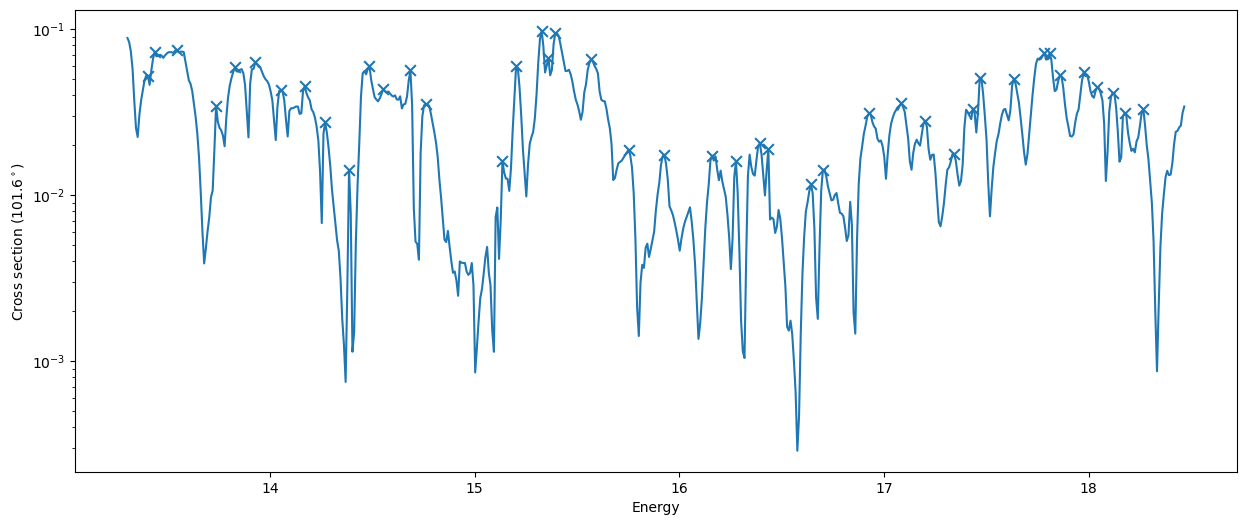

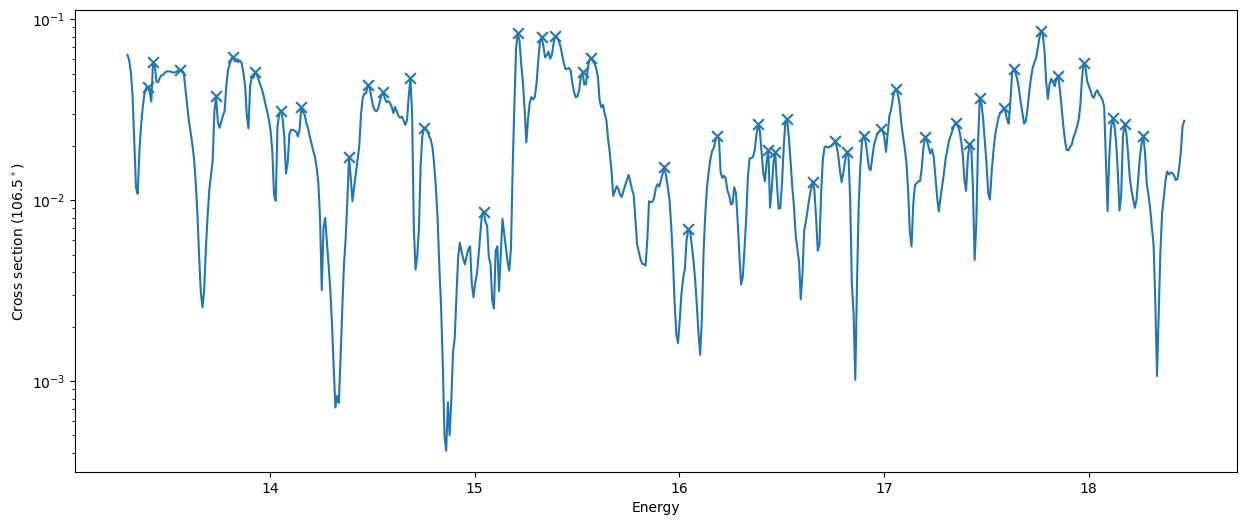

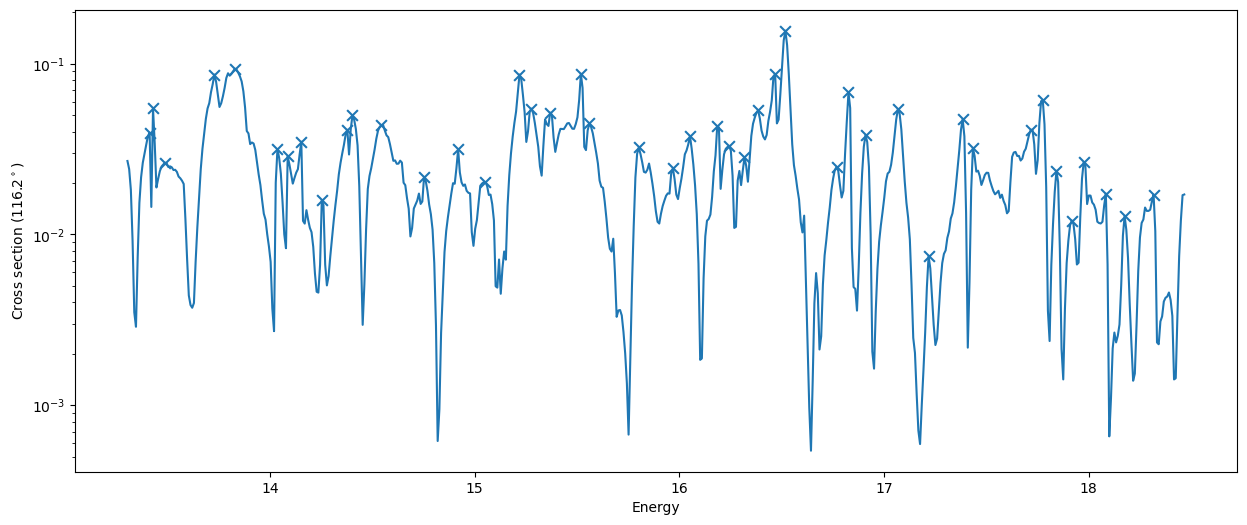

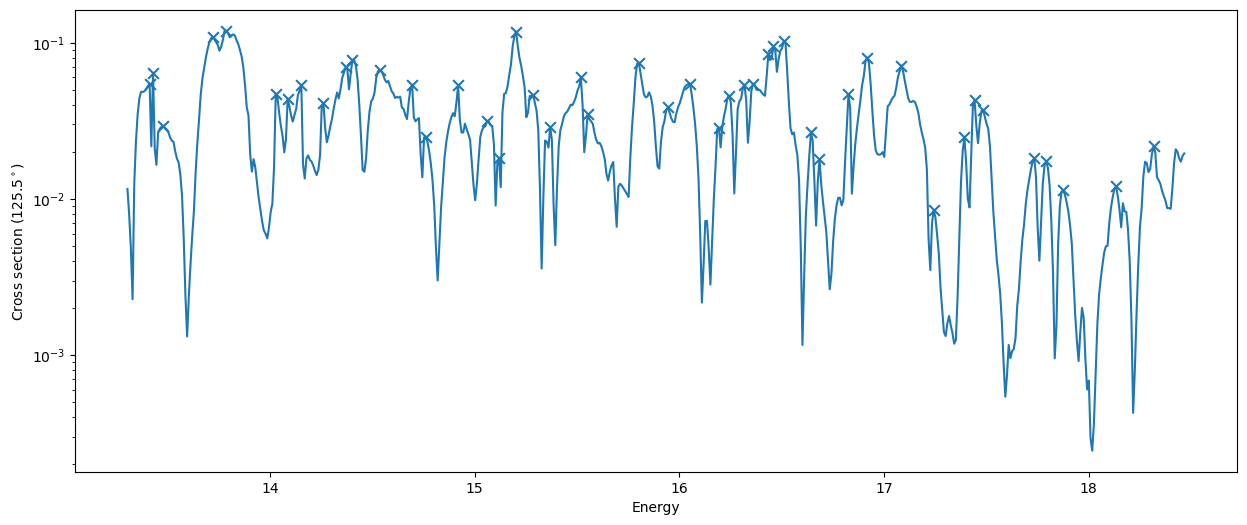

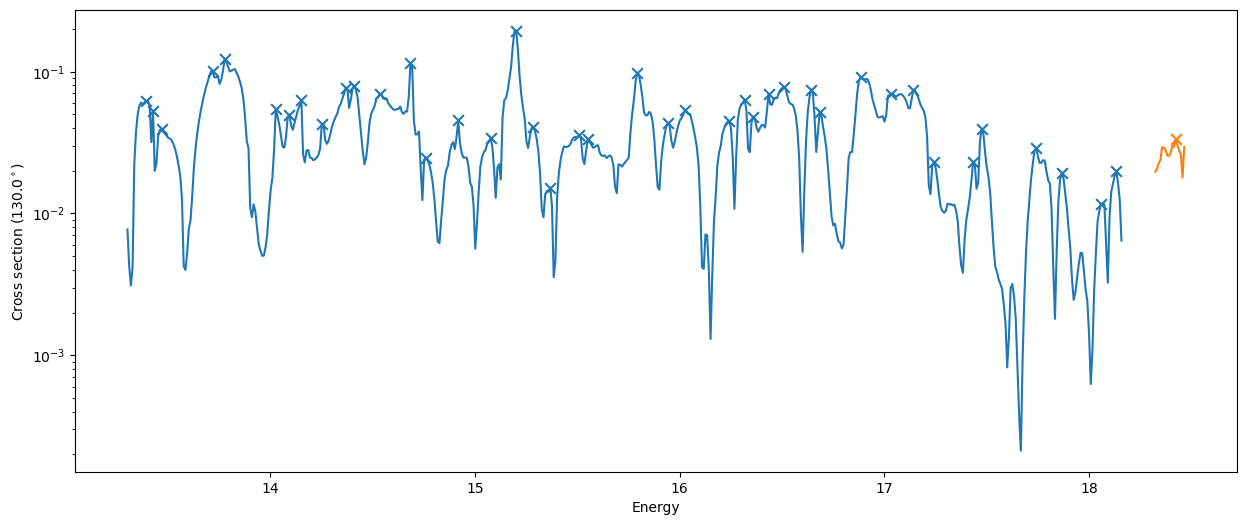

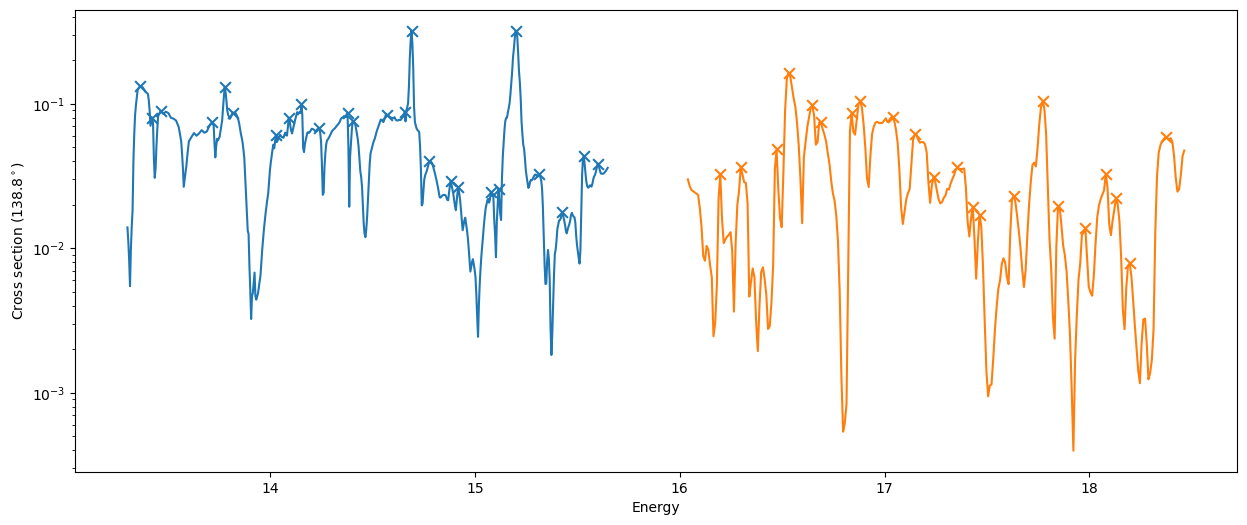

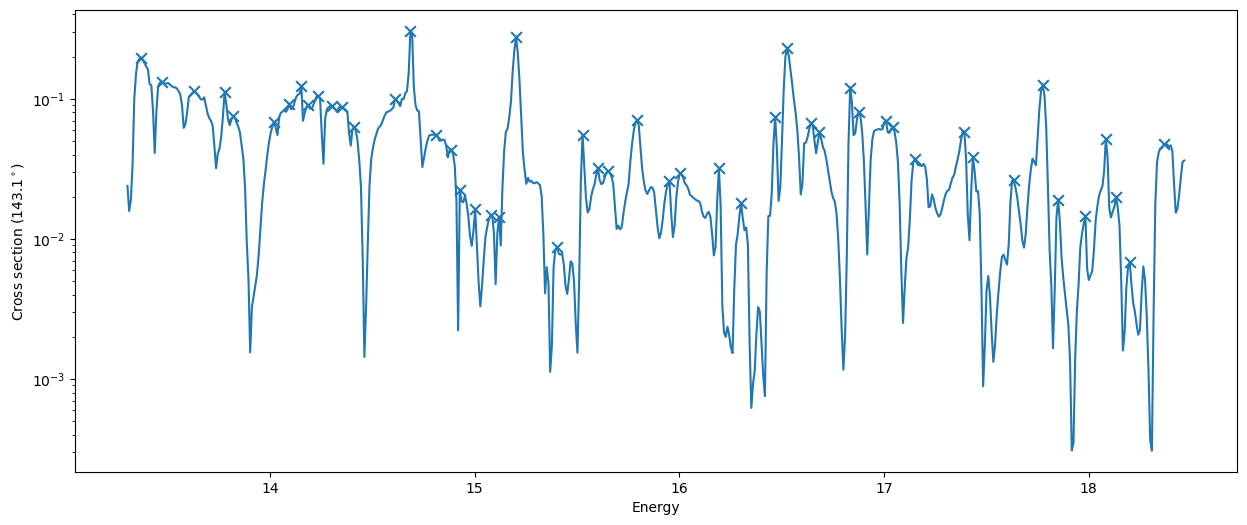

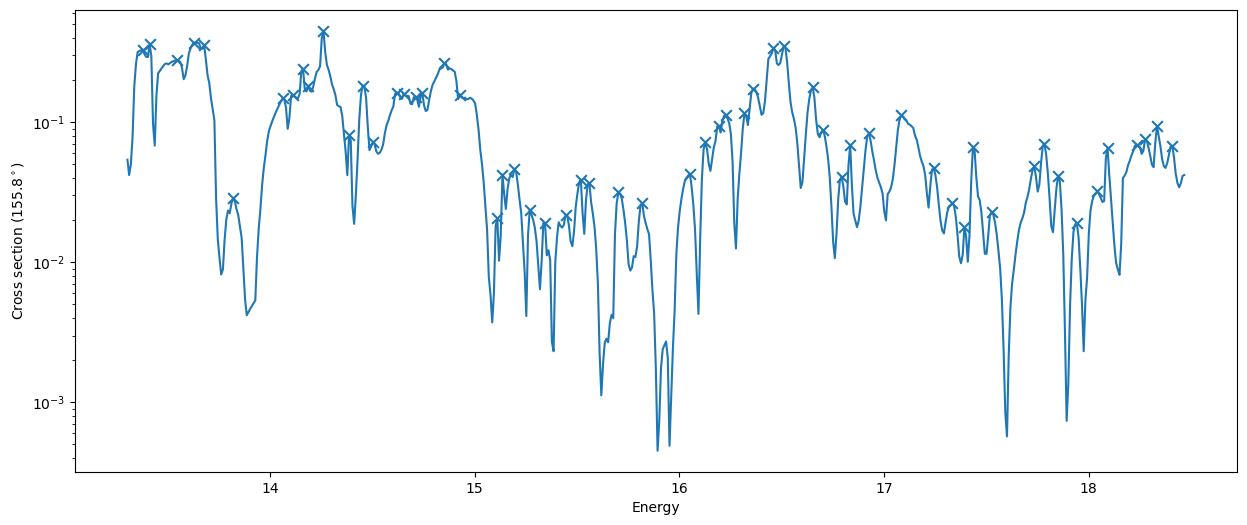

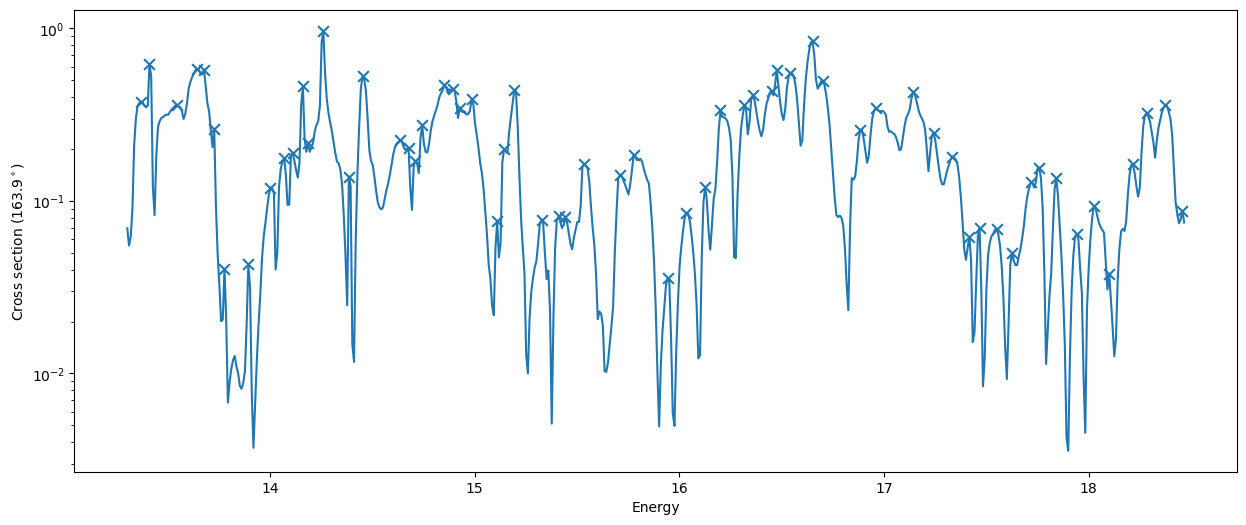

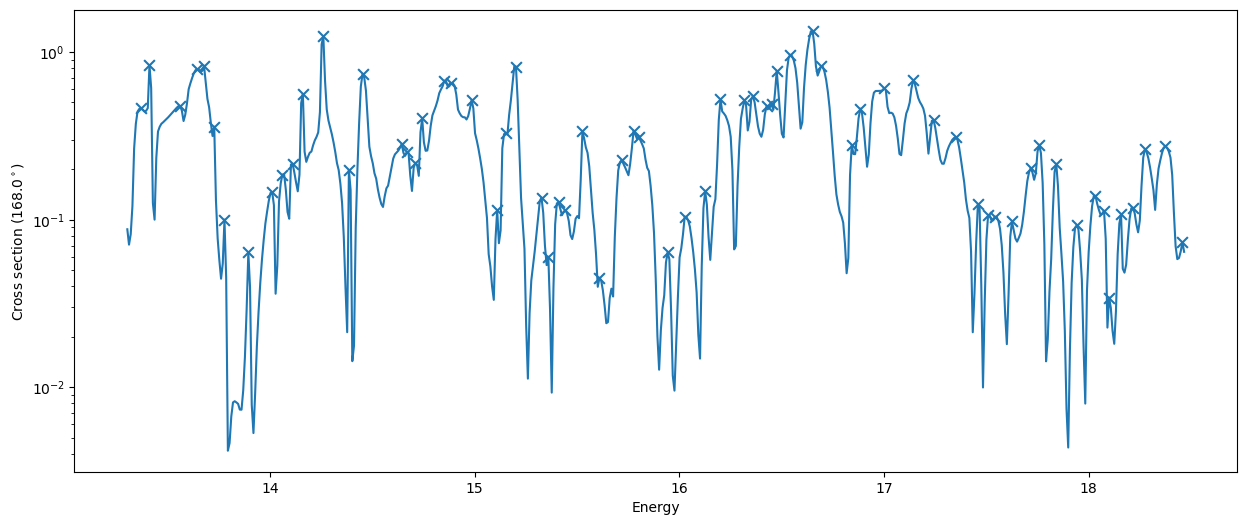

In [301]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma, 9.31)
functions.visualise_all_peaks(all_cs)

In [354]:
clusters, clustered_energies = functions.get_clusters_sort(all_cs)
"""print(len(clustered_energies))
for i in clustered_energies:
    print(min(i), max(i))"""

'print(len(clustered_energies))\nfor i in clustered_energies:\n    print(min(i), max(i))'

In [355]:
peaks = functions.get_all_peaks_lst(all_cs)

num_peaks_lst = [len(angle[1]) for angle in peaks]

print(max(num_peaks_lst), min(num_peaks_lst))


68 32


In [356]:
for cluster in clusters:
    print(len(cluster[1]))

print(len(clusters))

13
12
6
9
8
5
10
11
9
5
5
4
2
15
15
14
10
7
10
14
14
6
4
15
4
2
11
3
14
7
9
3
6
8
8
4
14
5
11
1
3
8
8
2
10
11
11
6
5
11
8
8
10
9
12
8
13
8
11
14
5
10
10
6
5
13
16
6
12
10
11
9
13
14
7
5
9
10
13
9
11
9
7
10
8
8
7
8
7
6
90


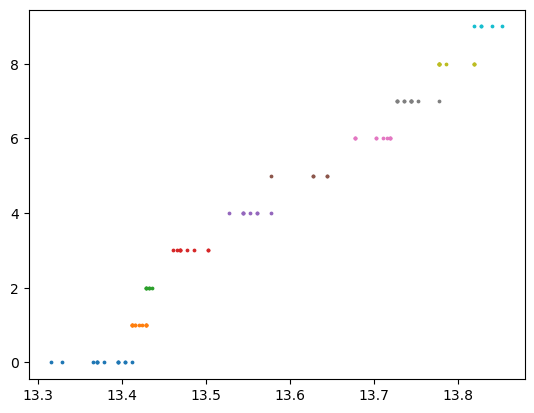

In [357]:
for i, energies in enumerate(clustered_energies[:10]):
    plt.scatter(energies, [i] * len(energies), s=3)

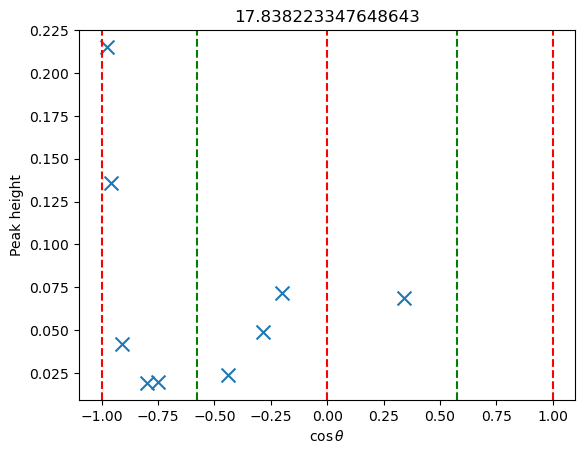

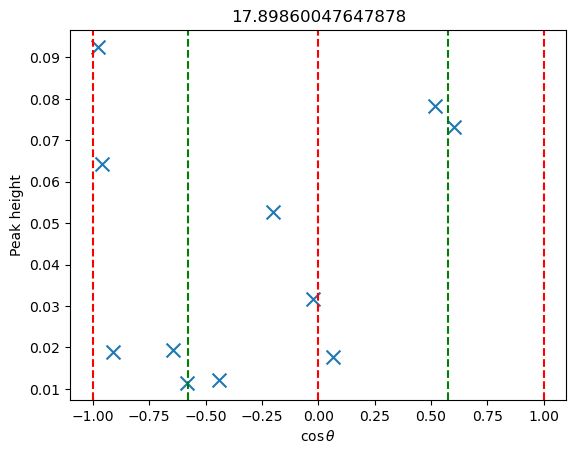

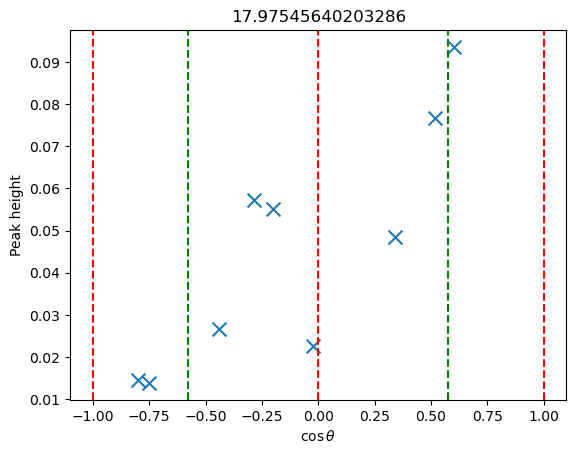

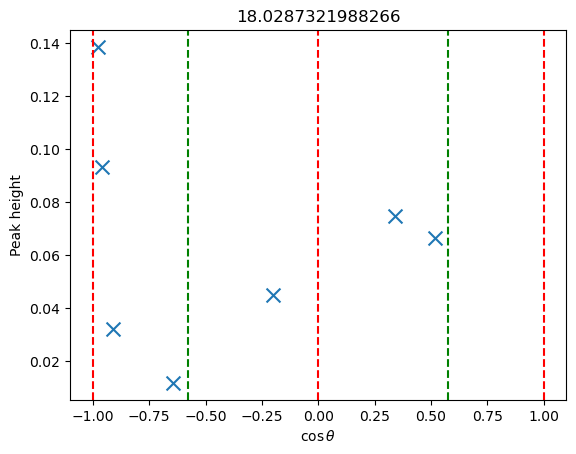

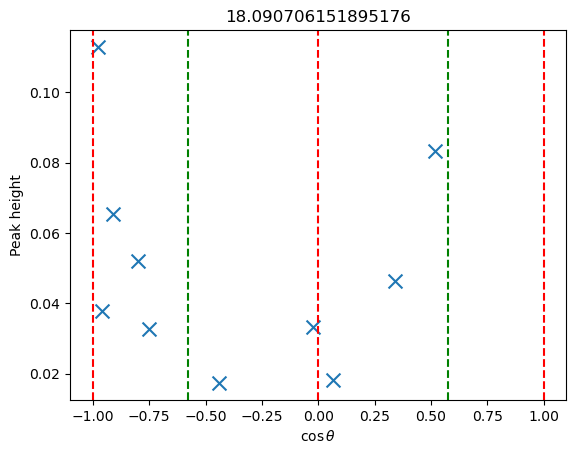

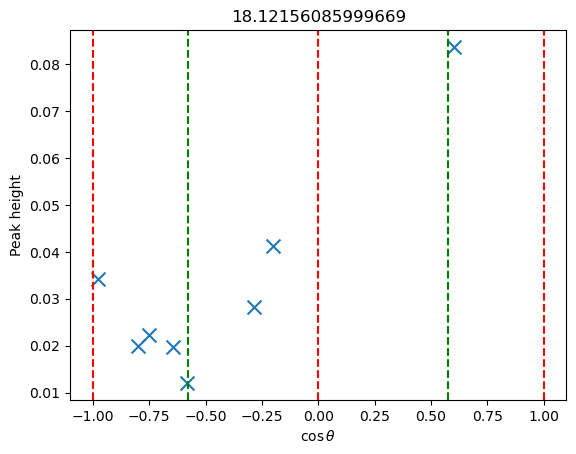

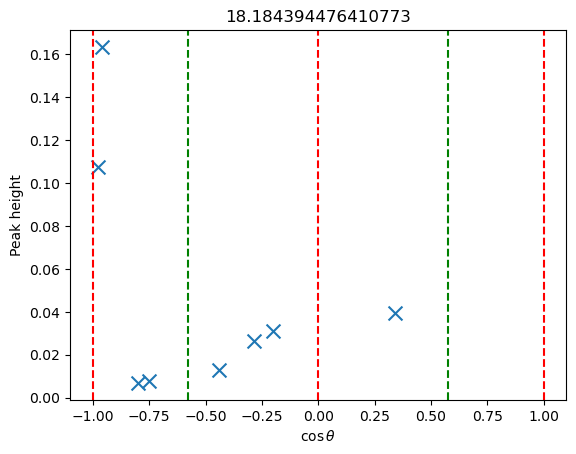

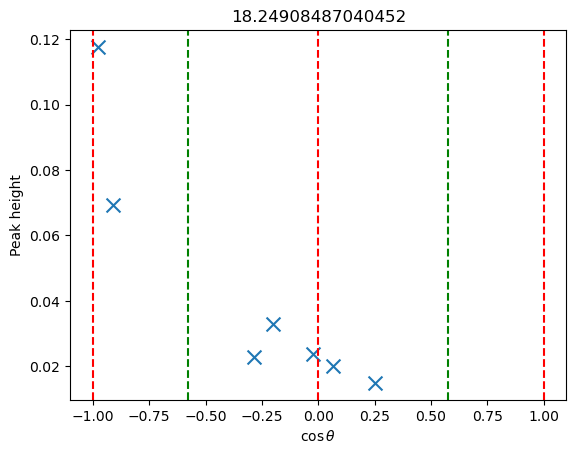

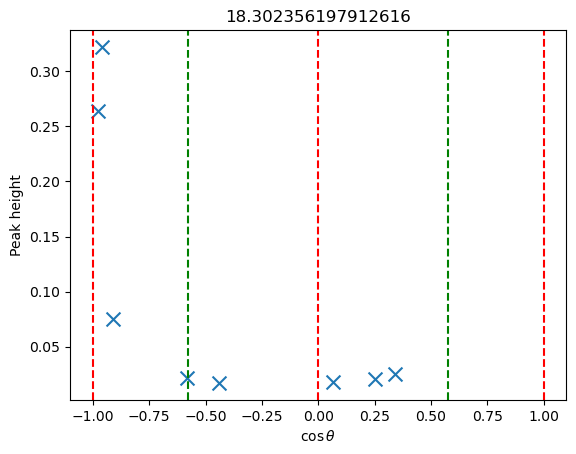

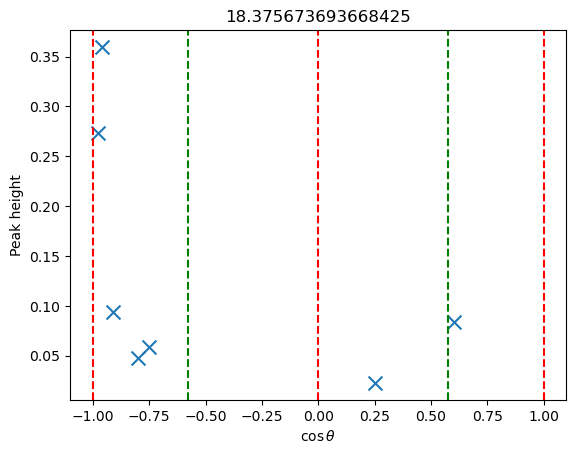

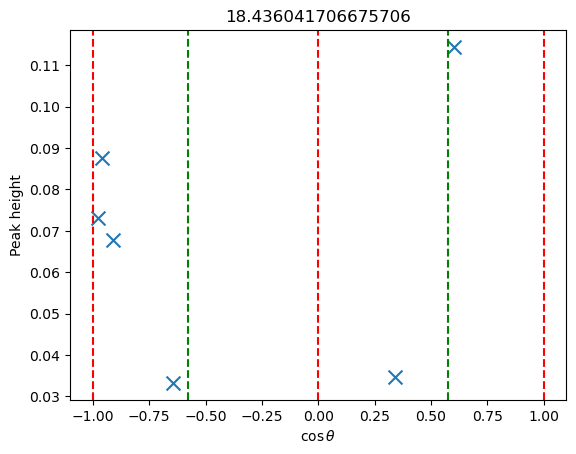

In [434]:
#green: zeroes
#red: maxima 
functions.visualise_clusters(clusters[79:], 2)

In [175]:
clusters_hdbscan, noise_hdbscan = functions.get_clusters_hdbscan(all_cs)

In [233]:
#functions.visualise_clusters(clusters_hdbscan[:7], 3)

In [228]:
clusters_linkage = functions.get_clusters_linkage(all_cs)

In [231]:
print(len(clusters_linkage))

89


In [352]:
#functions.visualise_clusters(clusters_linkage[18:], 4)

In [349]:
clusters_midpoints, partition_midpoints = functions.get_clusters_midpoints(all_cs)

In [351]:
print(partition_midpoints)

[13.39057775 13.40723541 13.42391295 13.45304403 13.48635938 13.51554354
 13.52804053 13.6029631  13.66126496 13.70290915 13.73206008 13.75288217
 13.79869078 13.83617054 13.84667092 13.87166154 13.88206972 13.8945696
 13.90289981 13.95277427 14.03606264 14.08603566 14.13600868 14.15266636
 14.17348845 14.21096822 14.23986037 14.32340752 14.35856369 14.39019176
 14.41918915 14.47934952 14.50017466 14.54828613 14.63574537 14.65656101
 14.66677581 14.68987636 14.72735613 14.79815124 14.86894636 14.91059054
 14.93557706 15.04801636 15.09616043 15.11741529 15.13130473 15.17711334
 15.21945344 15.26456613 15.32773882 15.33815087 15.34369008 15.38533427
 15.40270561 15.4193649  15.42697845 15.48528031 15.53942858 15.56856868
 15.62687055 15.66435031 15.74763868 15.78928287 15.87257124 15.98501055
 16.07662775 16.16408055 16.19025648 16.20990323 16.25986217 16.33898613
 16.39312357 16.43893217 16.46391868 16.50972729 16.59718008 16.60670695
 16.64002299 16.67213962 16.72331308 16.74829938 16.

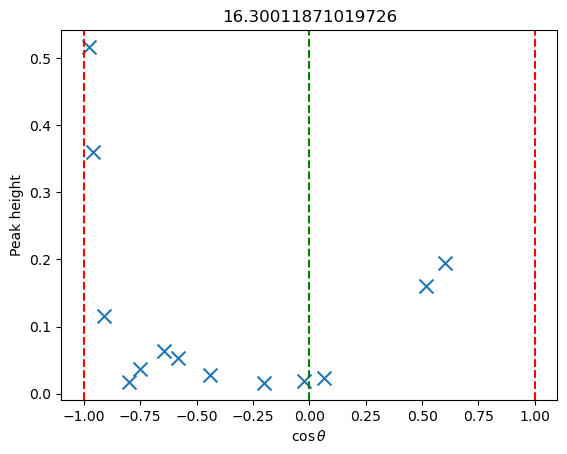

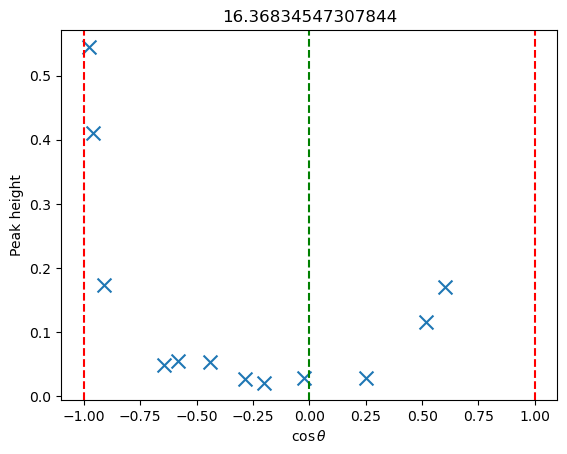

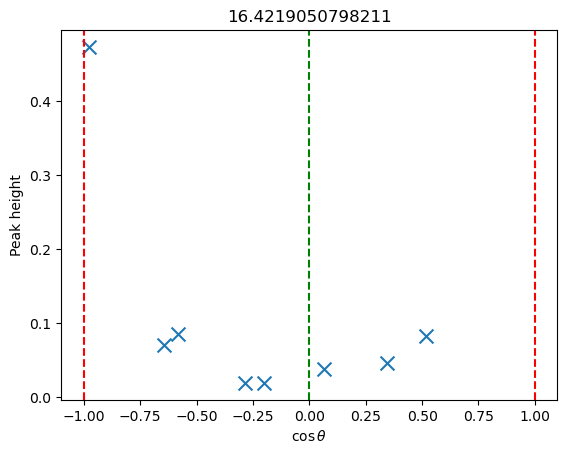

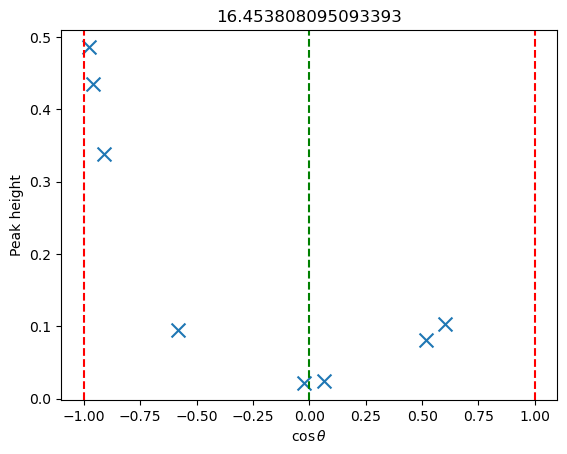

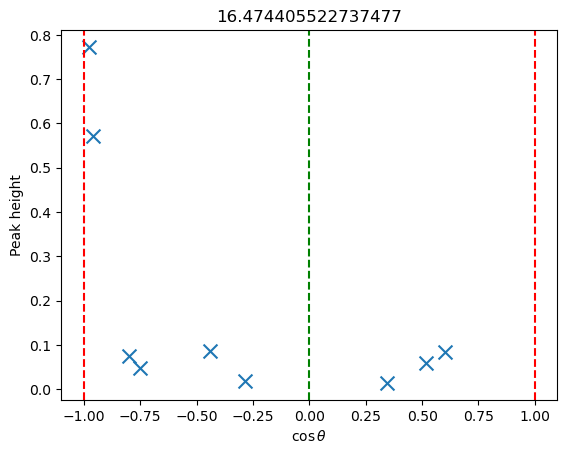

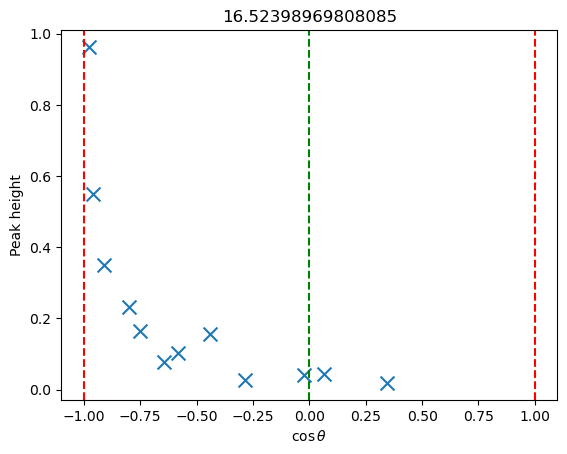

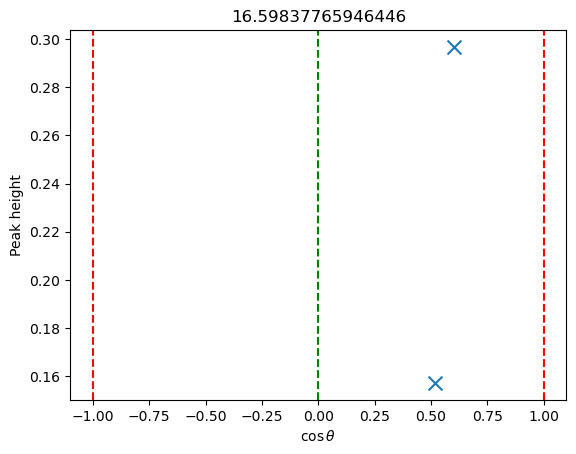

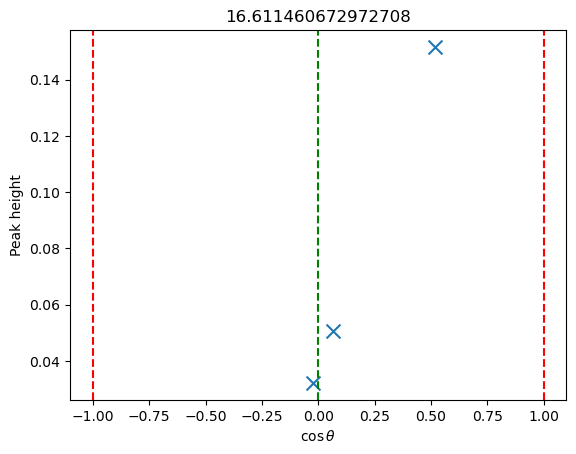

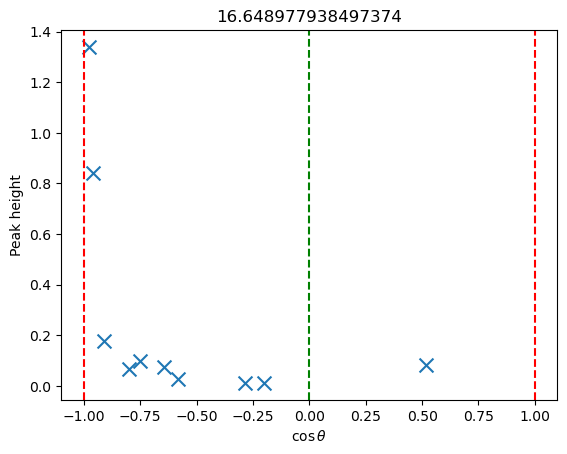

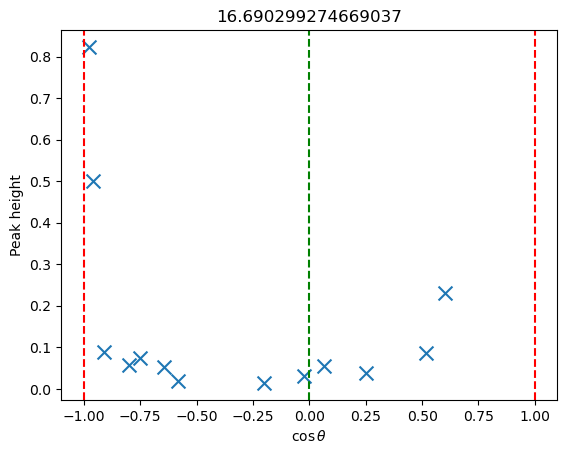

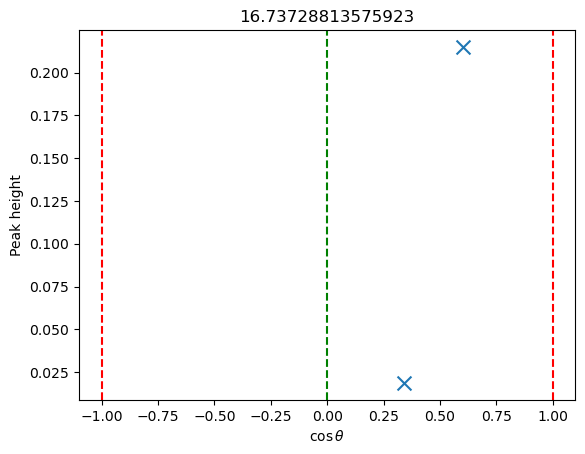

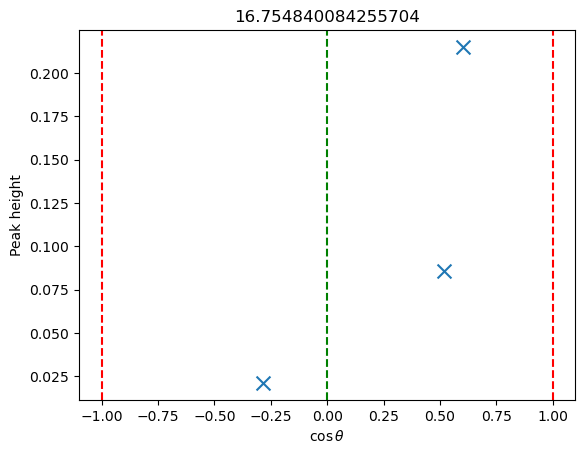

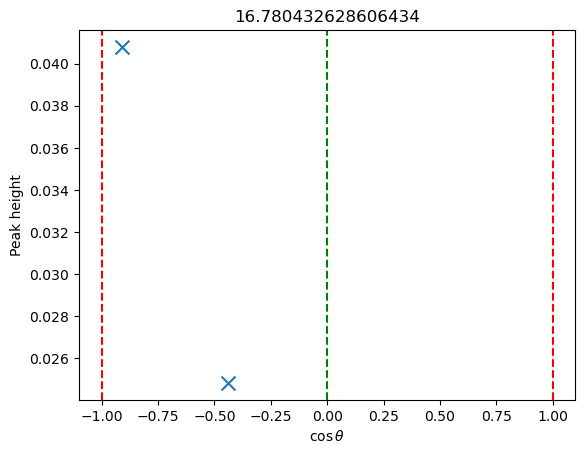

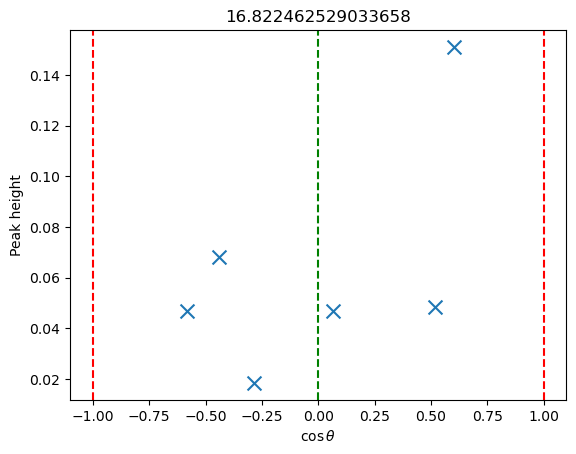

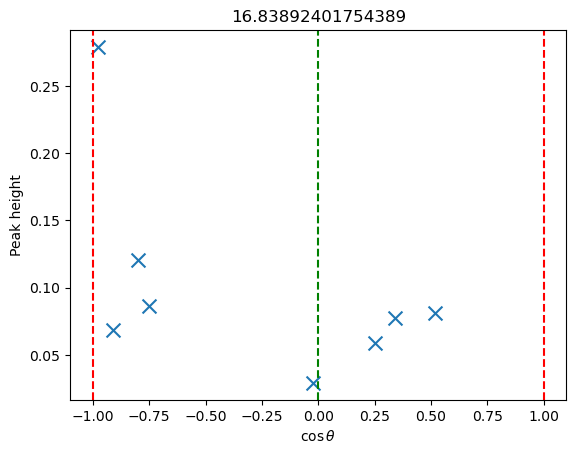

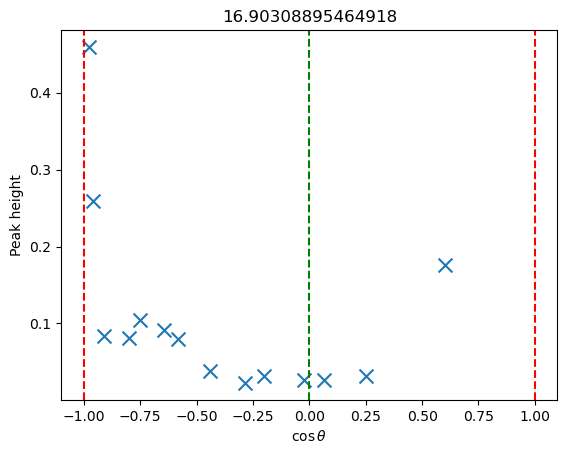

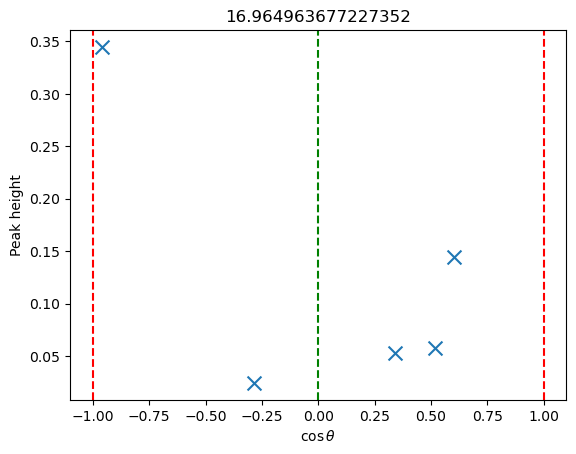

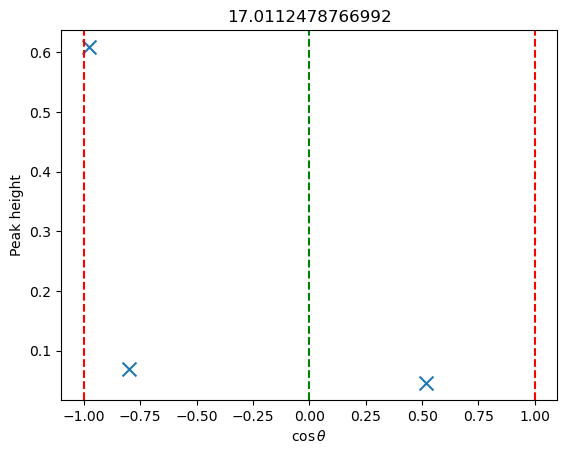

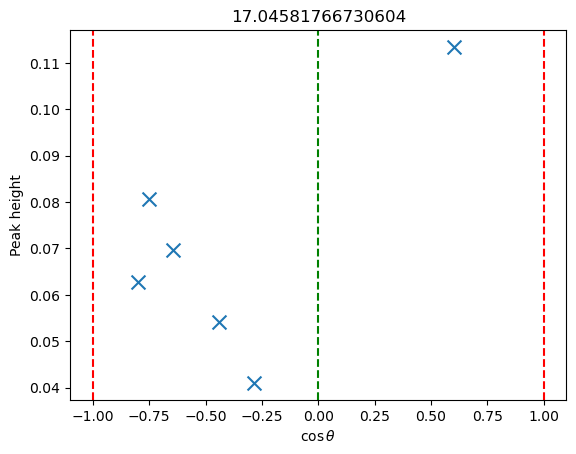

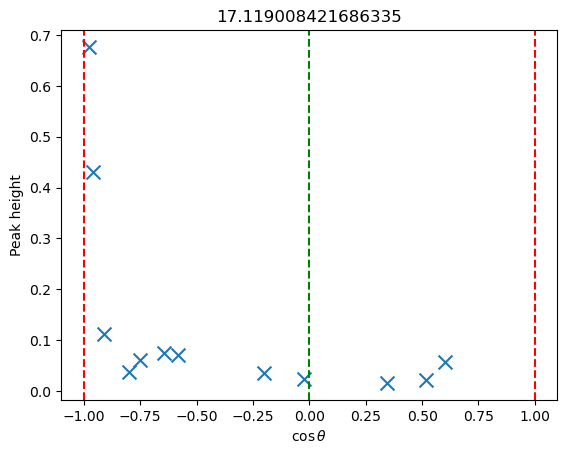

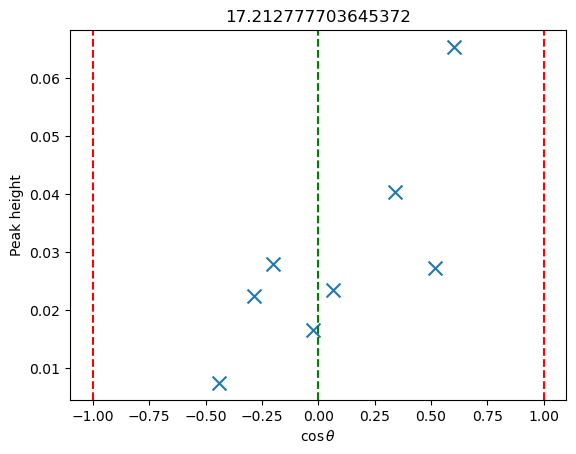

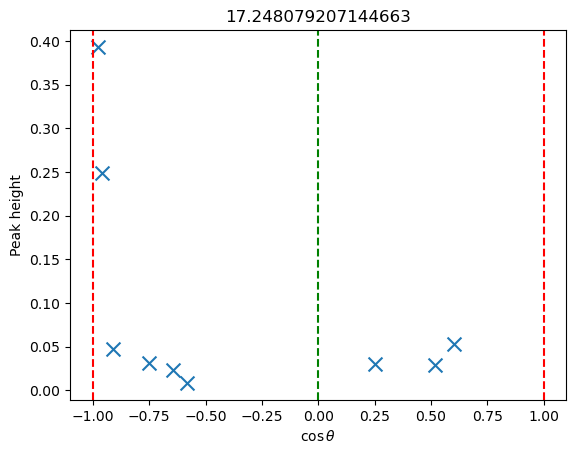

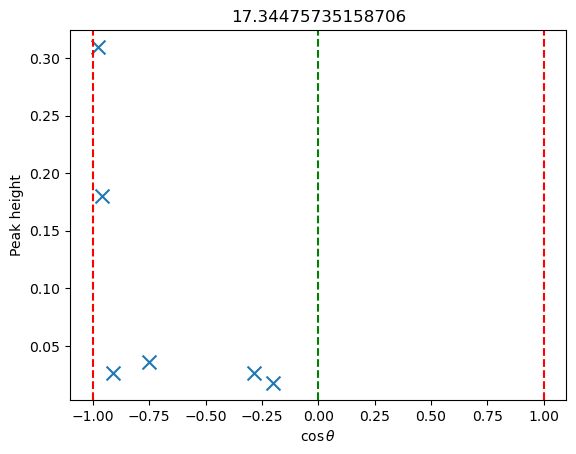

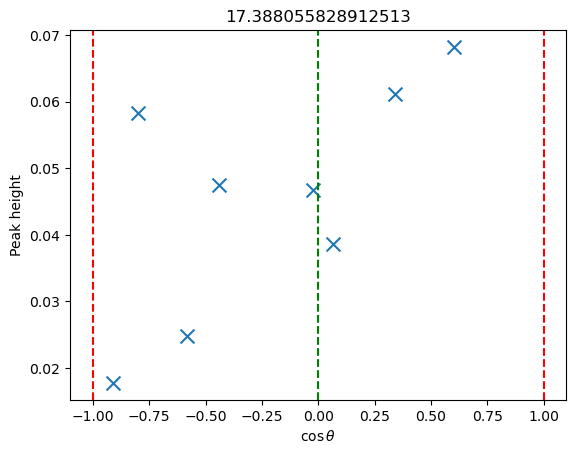

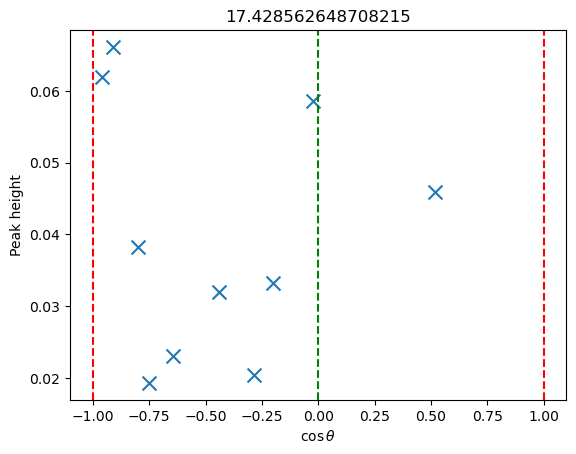

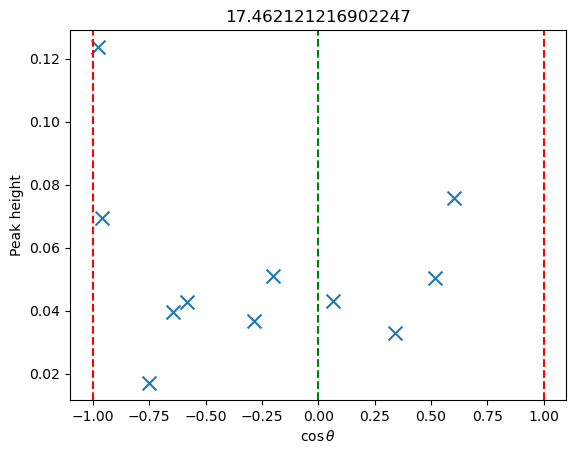

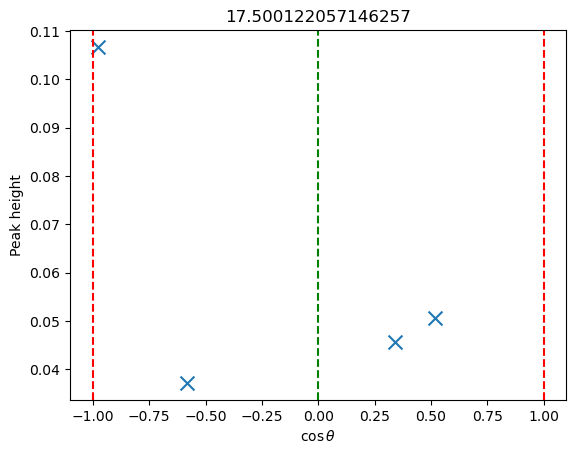

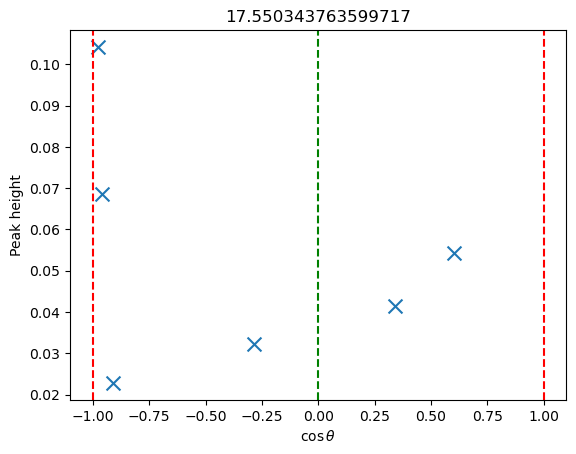

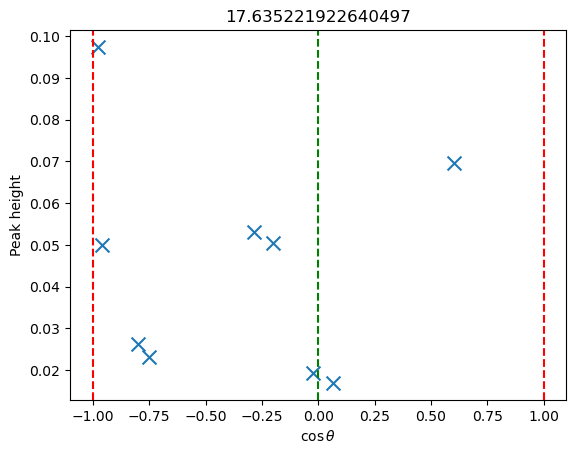

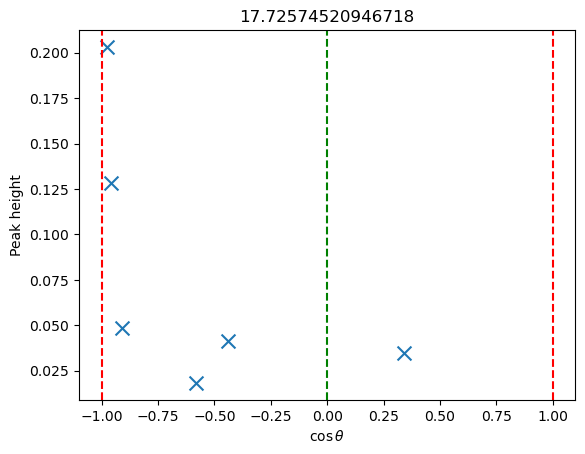

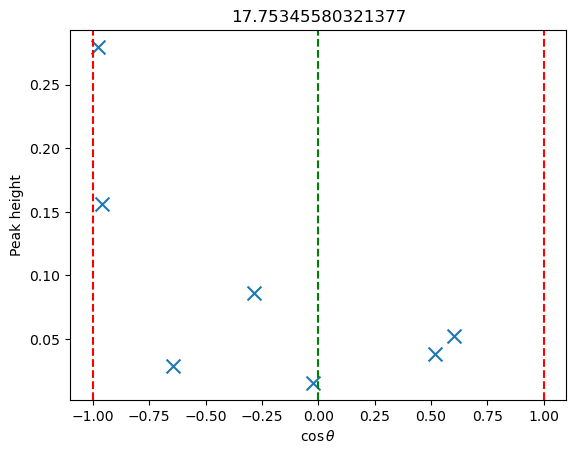

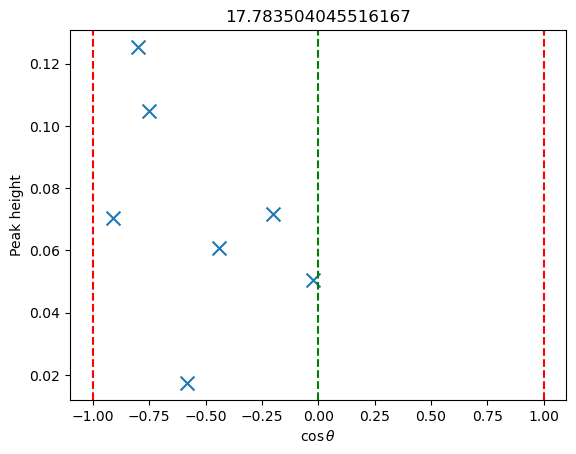

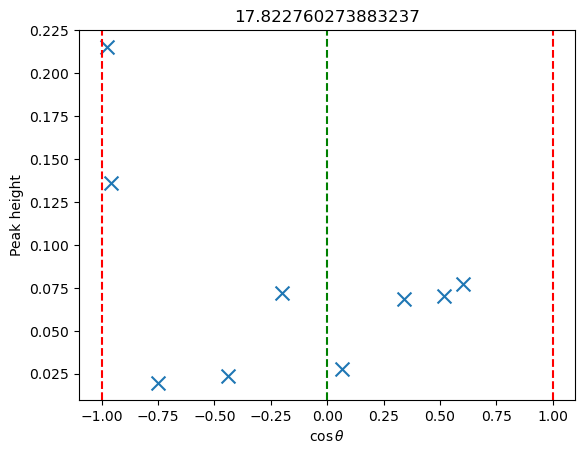

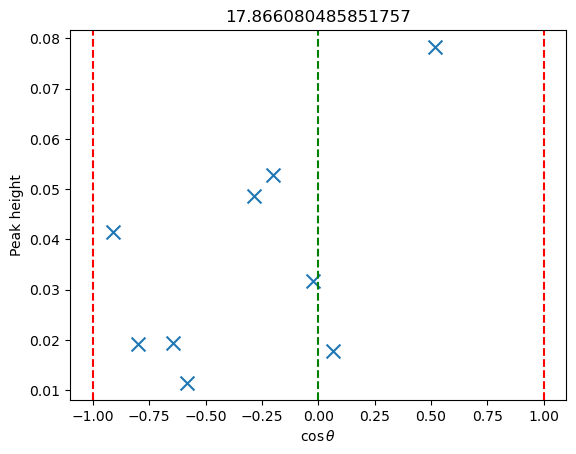

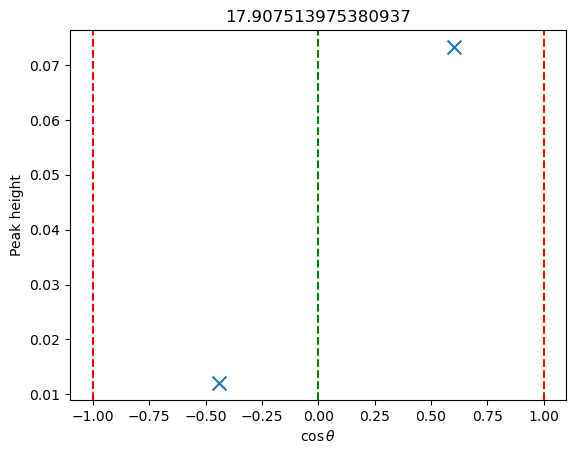

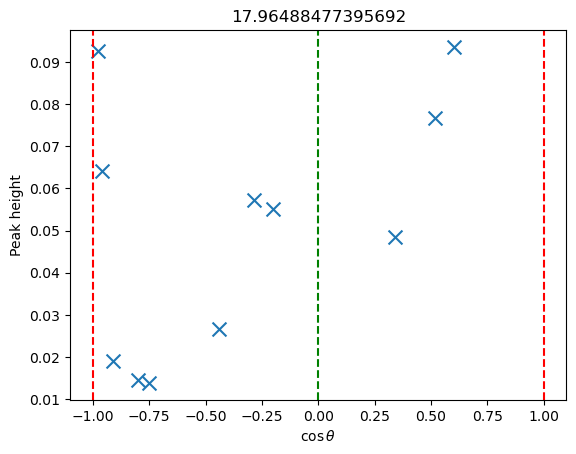

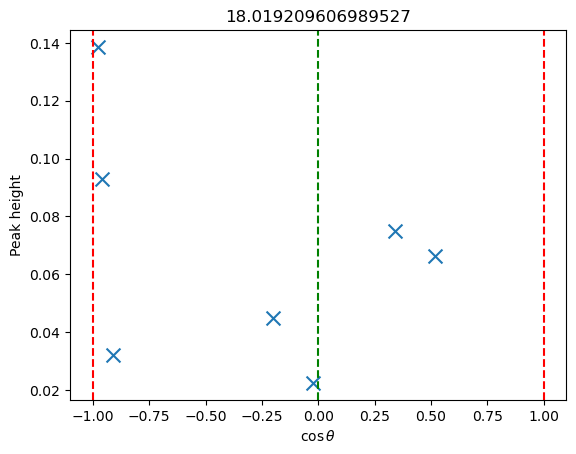

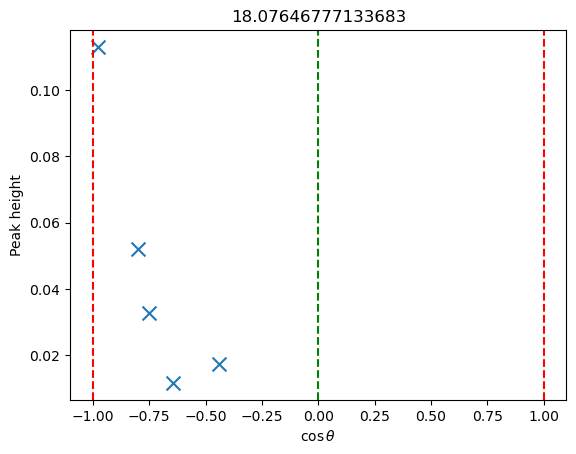

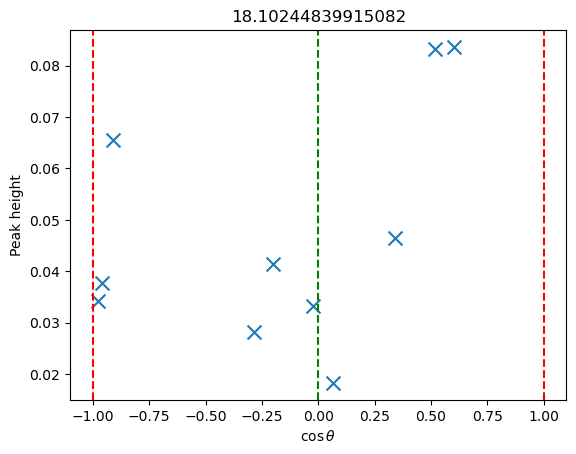

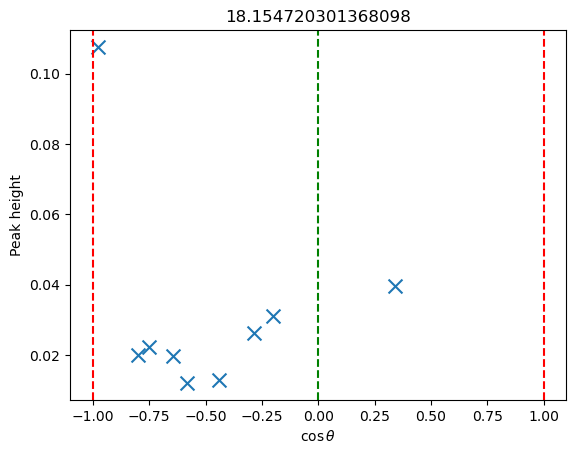

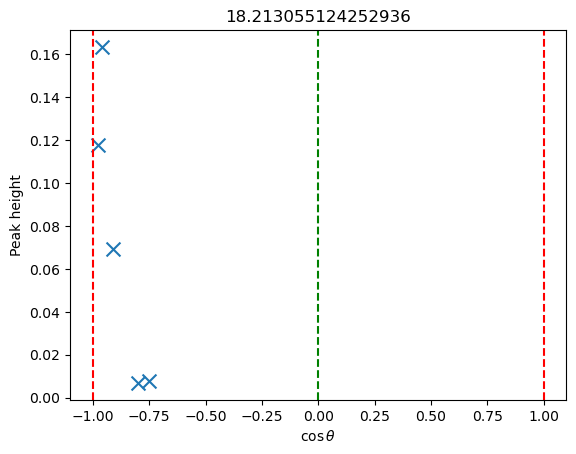

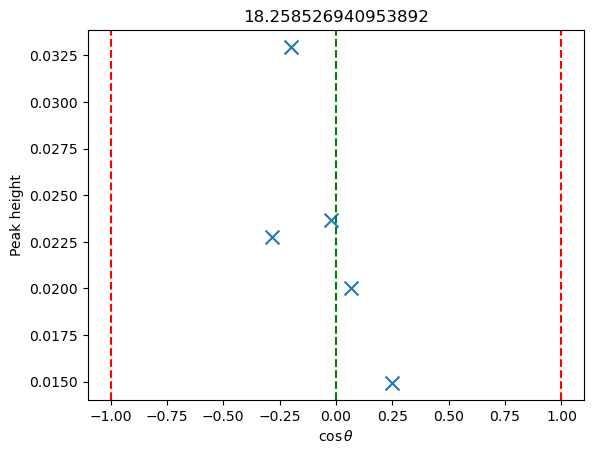

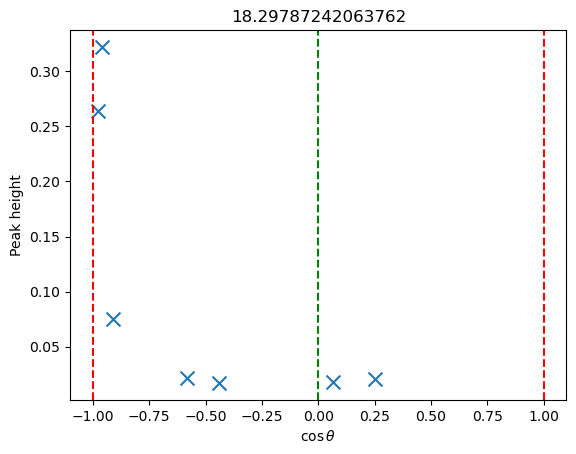

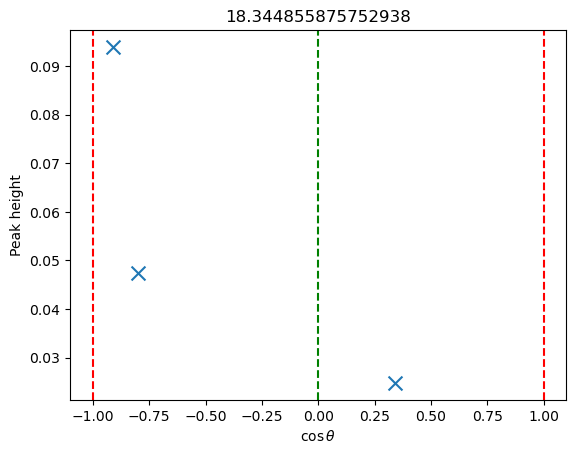

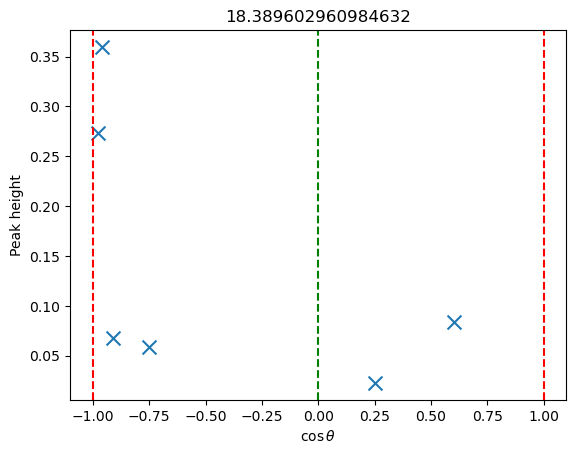

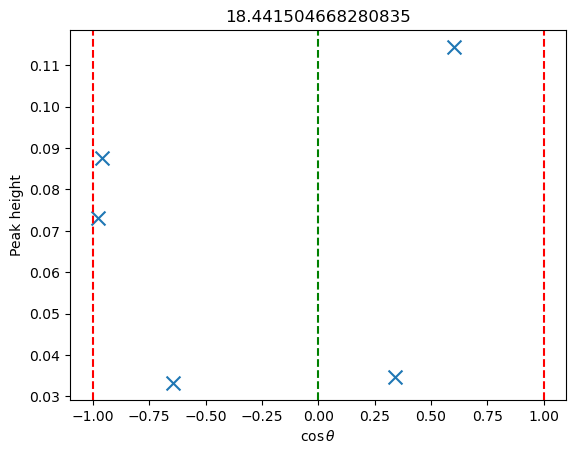

In [463]:
functions.visualise_clusters(clusters_midpoints[71:], 1)

In [377]:
repeat_a_factors = [0.001, 0.005, 0.01]

for i in repeat_a_factors:
    add_c_factors = [i + n*0.001 for n in range(5)]
    for j in add_c_factors:
        print("repeat_p= {}, new_cluster_p = {}".format(i, j))
        clusters_dp = functions.get_clusters_dp(all_cs, i, j)
        functions.get_dp_clusters_info(clusters_dp)

repeat_p= 0.001, new_cluster_p = 0.001
number of clusters: 783
783 clusters of size 1
Clusters with repeated angles: 0
repeat_p= 0.001, new_cluster_p = 0.002
number of clusters: 673
580 clusters of size 1
76 clusters of size 2
17 clusters of size 3
Clusters with repeated angles: 0
repeat_p= 0.001, new_cluster_p = 0.003
number of clusters: 122
3 clusters of size 2
20 clusters of size 3
10 clusters of size 4
16 clusters of size 5
22 clusters of size 6
13 clusters of size 7
13 clusters of size 8
6 clusters of size 9
6 clusters of size 10
5 clusters of size 11
5 clusters of size 12
2 clusters of size 13
1 clusters of size 15
Clusters with repeated angles: 14
repeat_p= 0.001, new_cluster_p = 0.004
number of clusters: 102
2 clusters of size 2
6 clusters of size 3
8 clusters of size 4
11 clusters of size 5
11 clusters of size 6
15 clusters of size 7
13 clusters of size 8
11 clusters of size 9
4 clusters of size 10
6 clusters of size 11
8 clusters of size 12
4 clusters of size 13
1 clusters of

In [378]:
clusters_dp_chosen = functions.get_clusters_dp(all_cs, 0.001, 0.005)

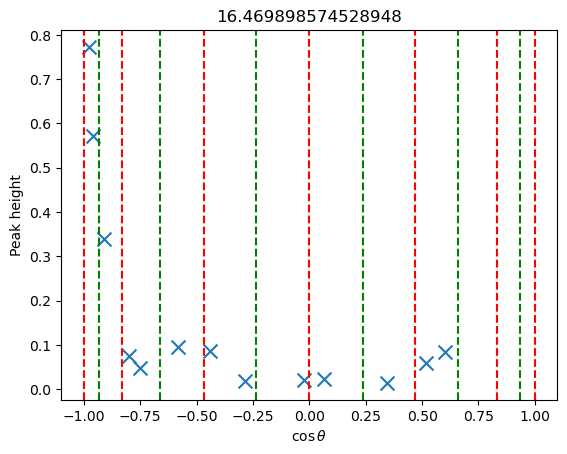

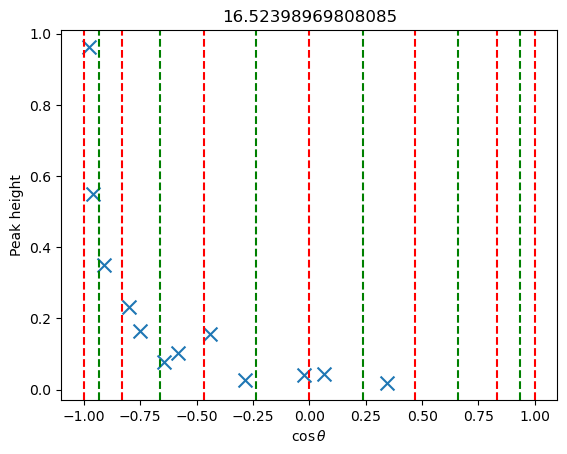

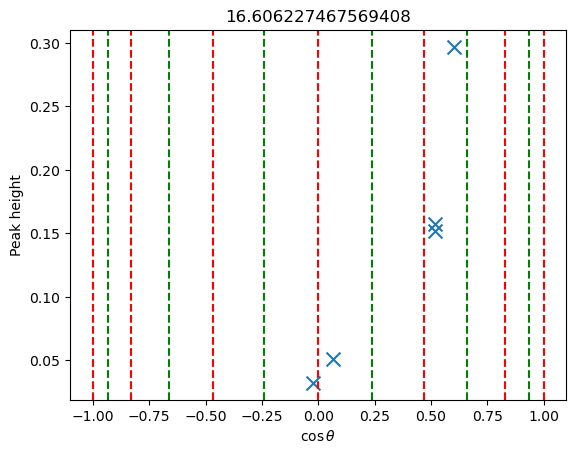

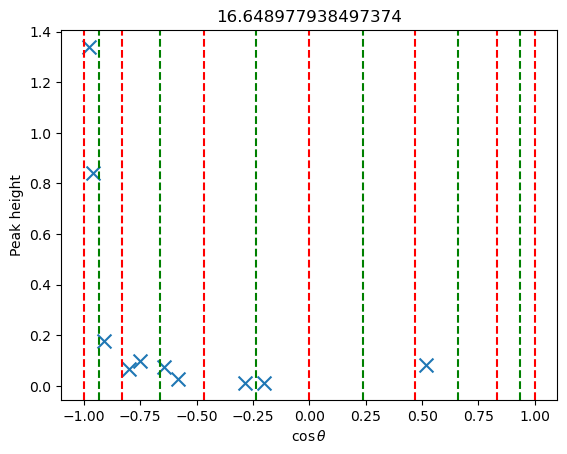

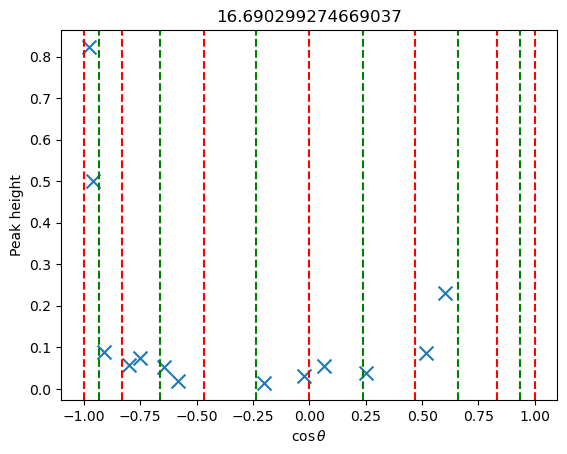

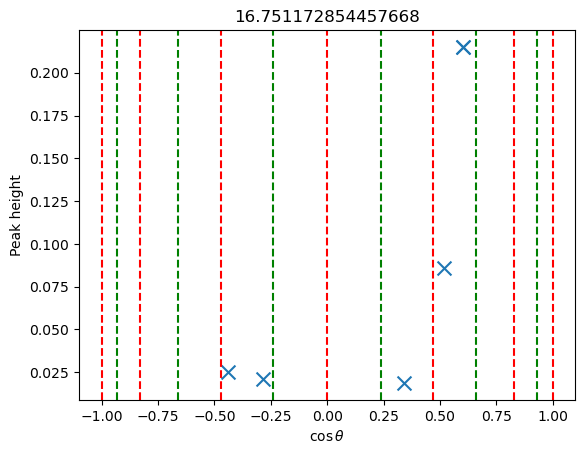

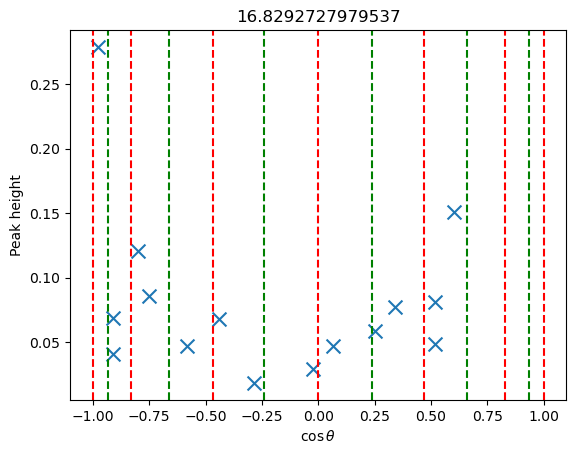

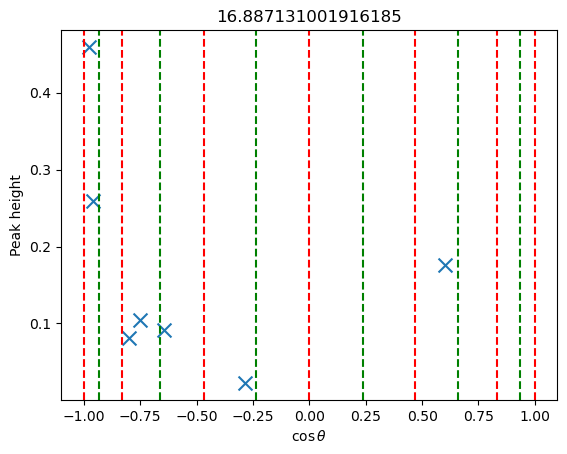

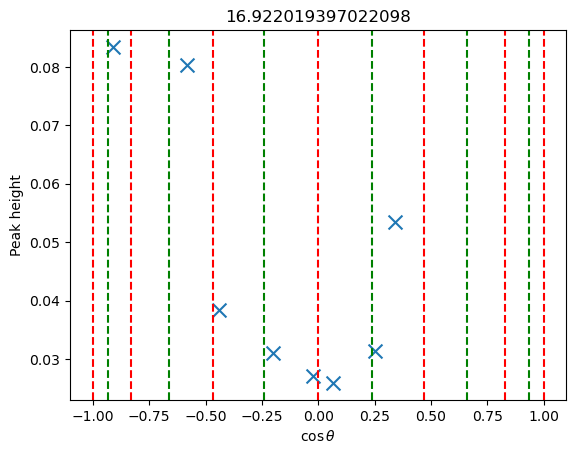

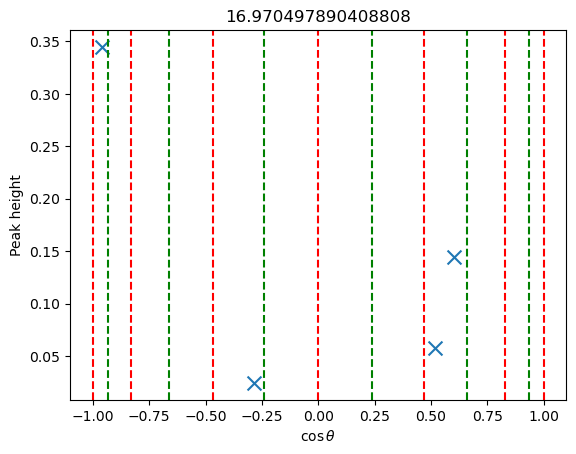

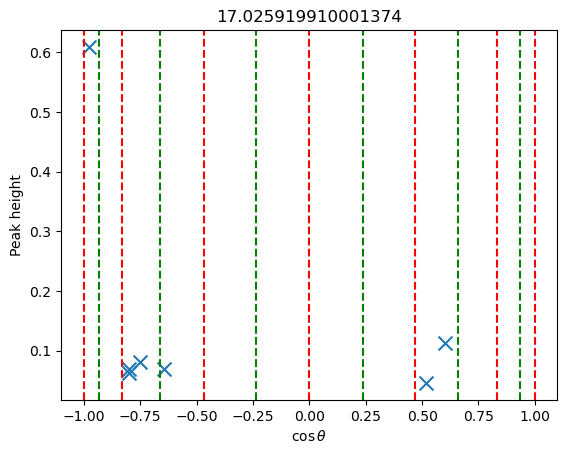

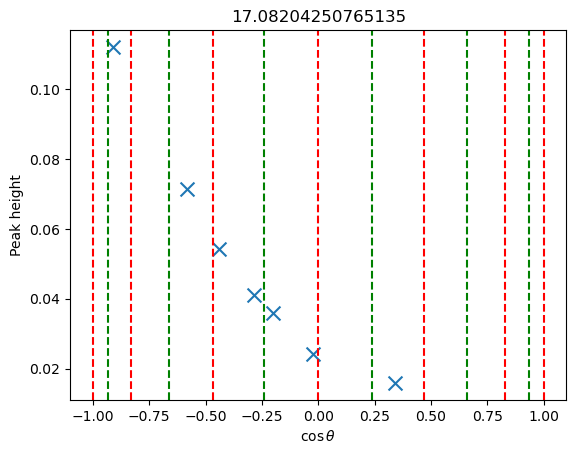

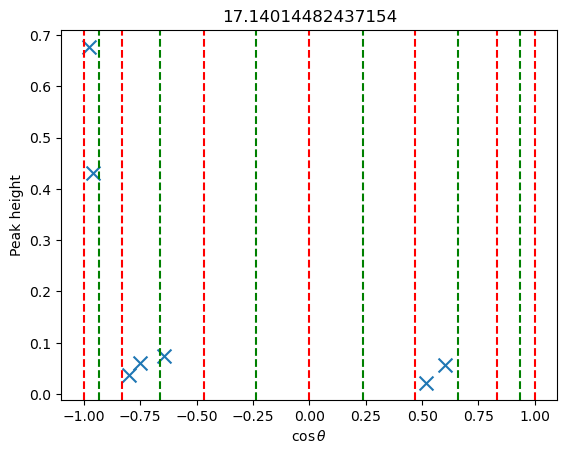

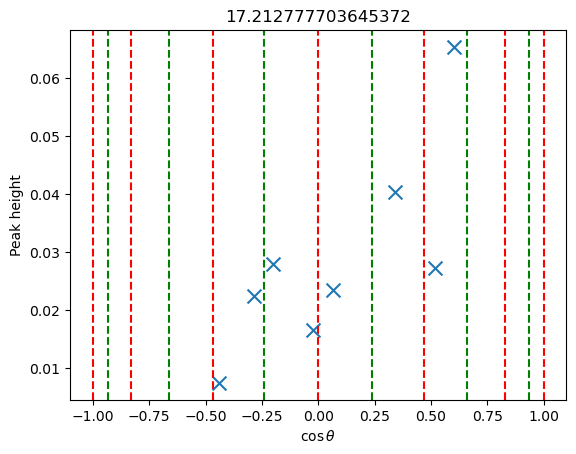

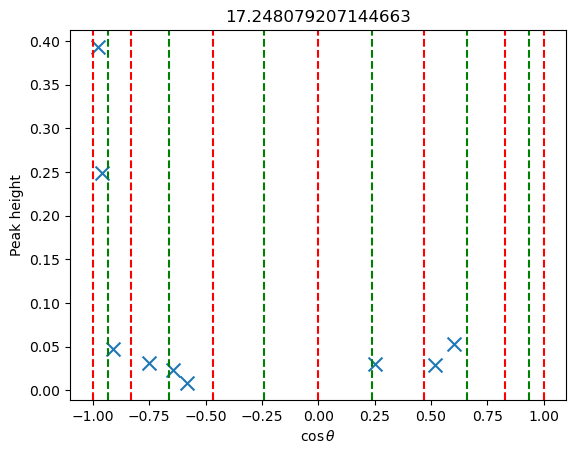

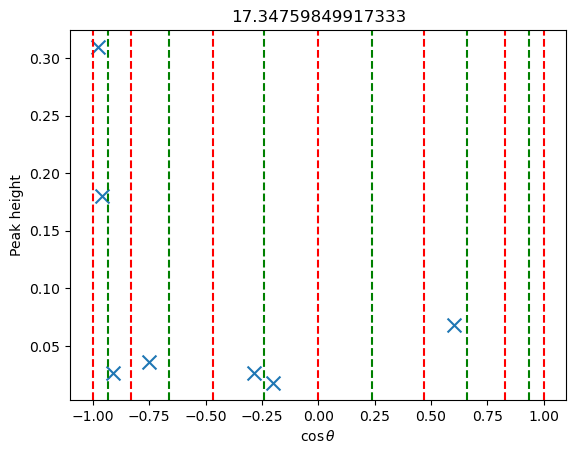

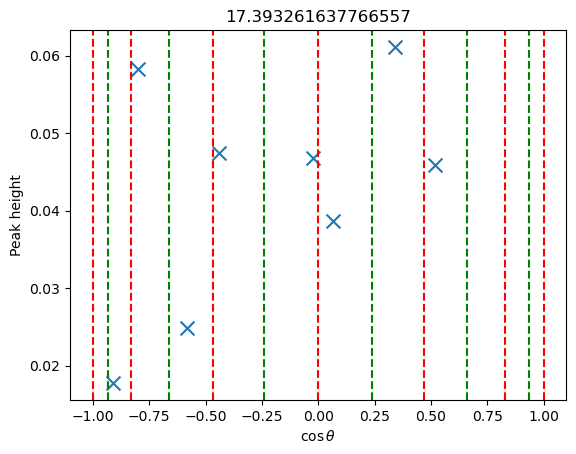

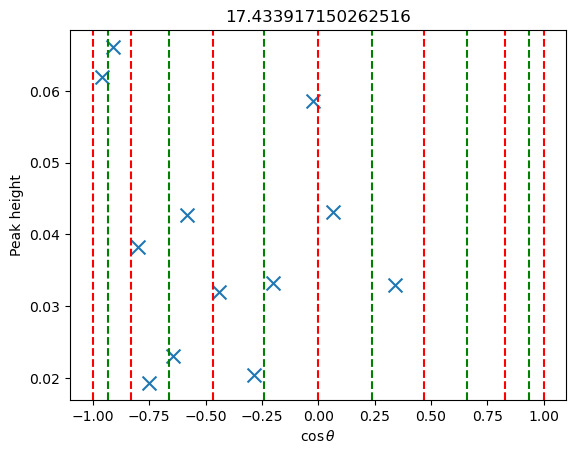

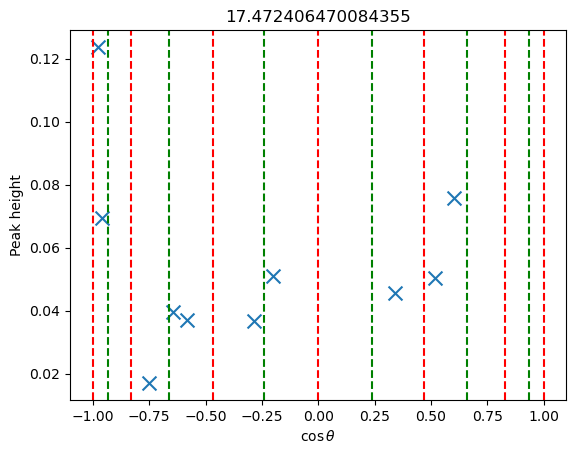

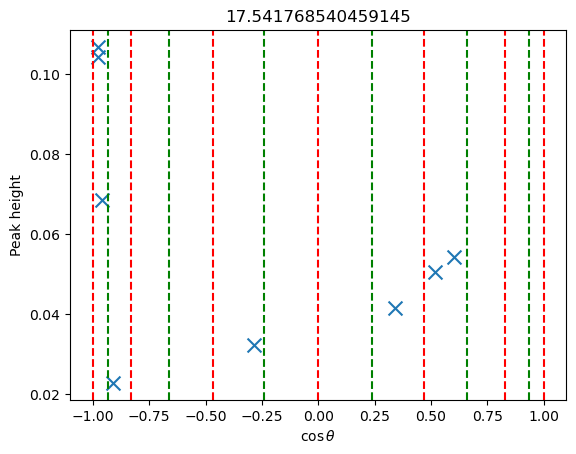

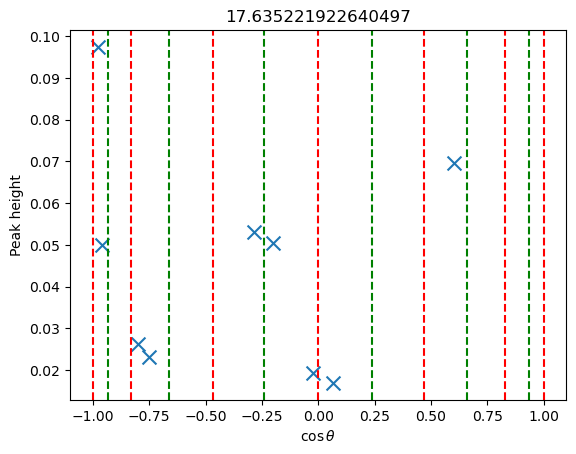

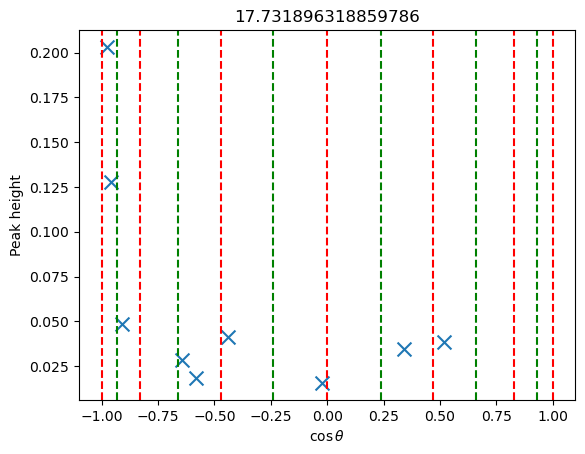

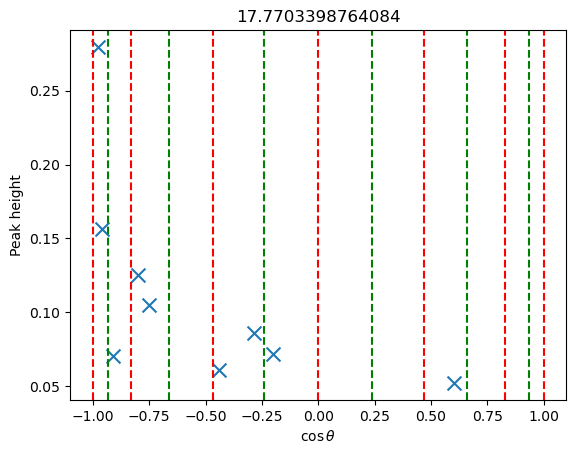

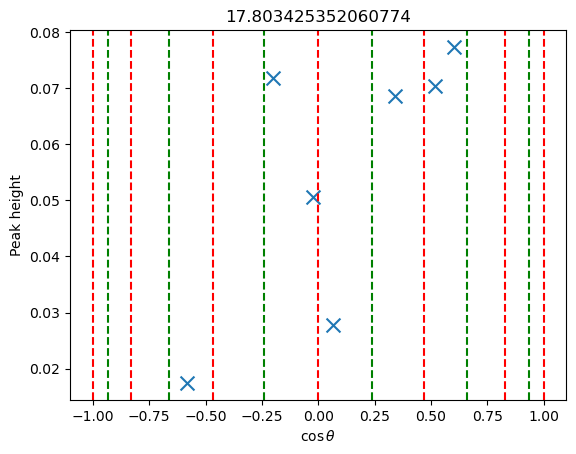

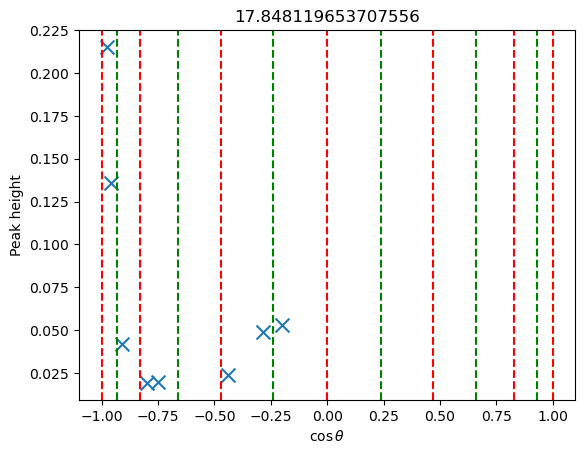

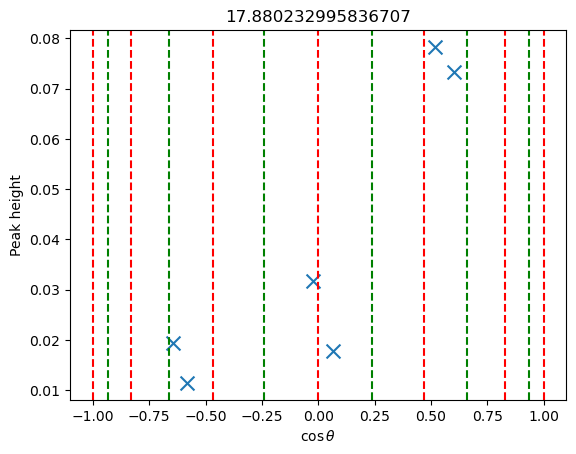

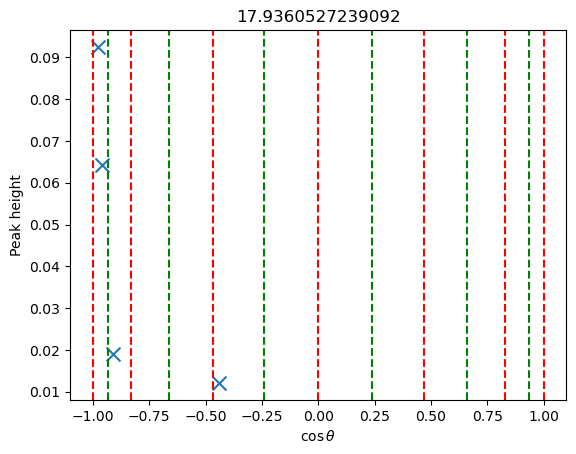

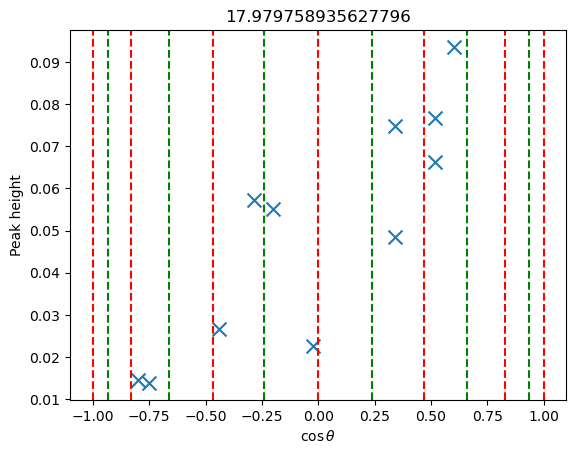

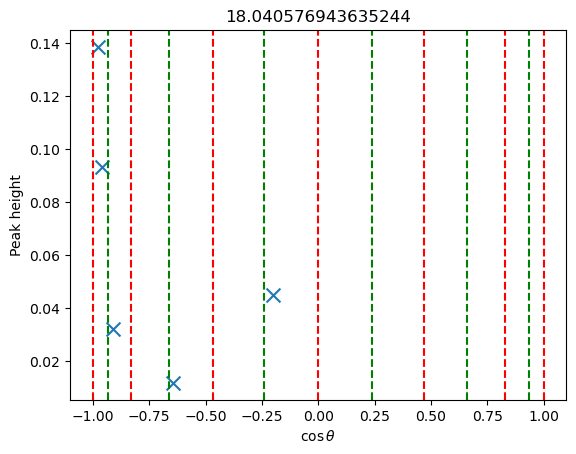

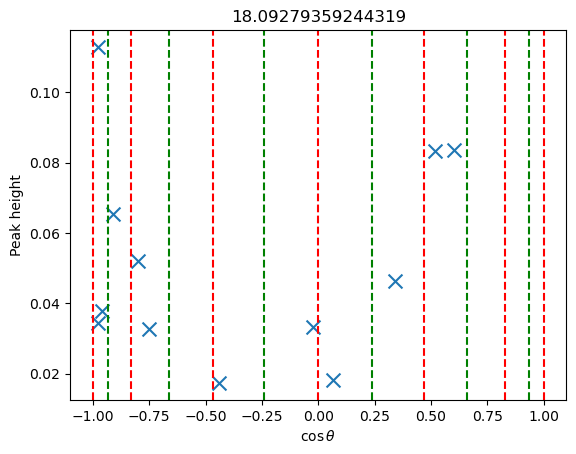

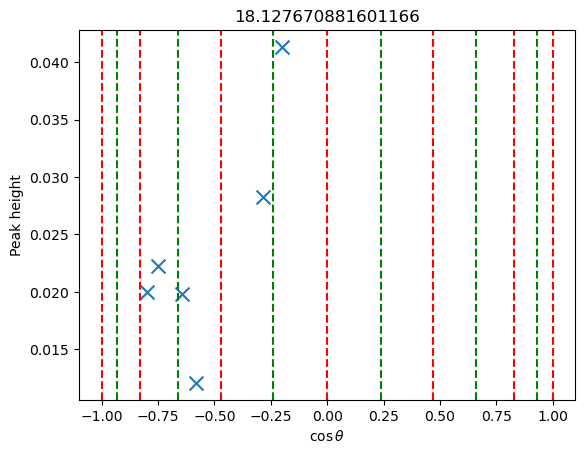

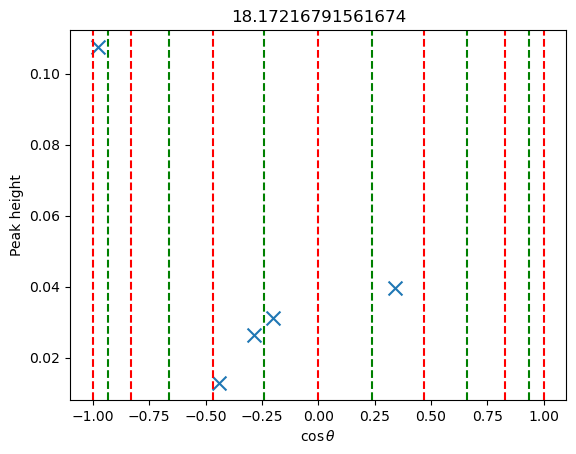

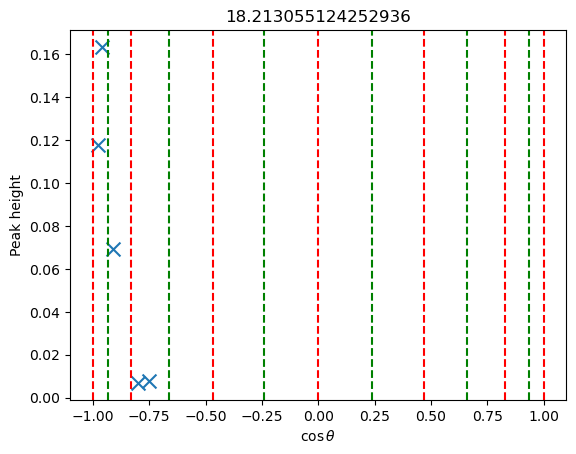

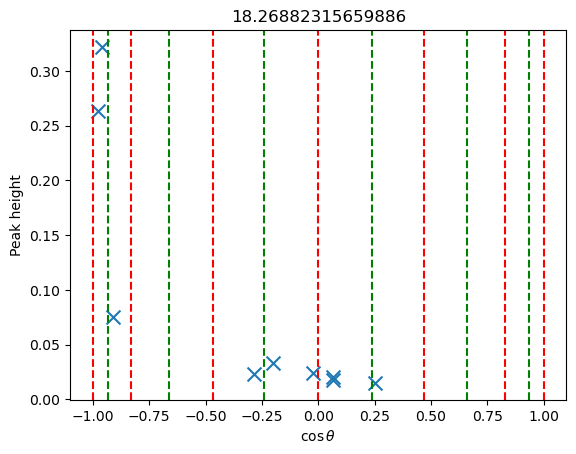

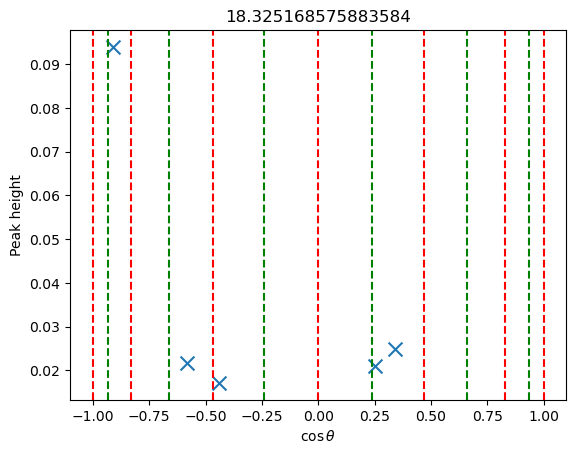

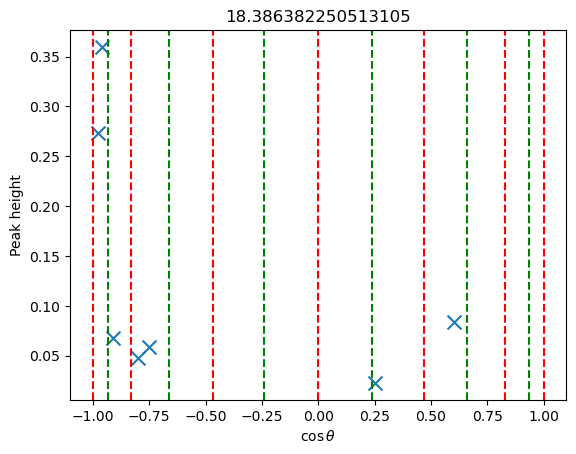

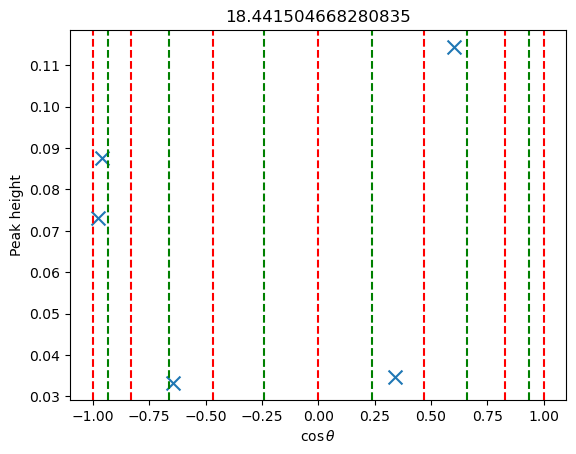

In [481]:
functions.visualise_clusters(clusters_dp_chosen[55:], 6)